# VERDE — Dataset Analysis & Build Report (v3)
### Smart Recycling and Waste Segregation Assistant — adding GlobalWasteData and a Hugging Face waste dataset to the frozen 2.0 dataset

**Why this notebook exists.** Version 2 gave 14,424 clean images in 8 UK-oriented classes. Three final models score 93–95% on its test set but only 42–54% on our own photos (the *domain gap*). One explanation is that the training data is too narrow, so this notebook asks whether two larger public sources can widen it. It maps their labels to our 8 classes, removes anything we already have, checks that nothing leaks into the 2.0 test set or our real photos, inspects what is actually inside the new classes, and builds a split of the **new images only**. The 2.0 split stays frozen so every later comparison uses the same test set.

**Sources.** (1) the 2.0 dataset (base, frozen); (2) **GlobalWasteData** (GWD, DFKI), imported to Kaggle as the dataset `global-waste-dataset`; (3) the Hugging Face dataset **`4w4kt/waste-dataset-image`** (28,840 images, 9 classes).

**Inputs to attach (Kaggle).** Add Input → (a) Notebook Output: `verde-data-analysis-2-0`; (b) your dataset `global-waste-dataset`; (c) your real-photo dataset (`images_verde`; file names `class_item_number.jpg`). Turn **Internet = On** before starting the session (Section 1 downloads the Hugging Face dataset). A GPU is not needed. **Run time:** not yet measured; most of it is Section 3 (reading every new image once) and Section 8 (writing the standardised copies).

**Outputs** (in `/kaggle/working`): `new_inventory.csv`, `label_mapping.csv`, `new_dhash.npz`, `image_properties.csv`, `dedup_report.csv`, `leakage_report.csv`, `new_images_split.csv`, `verde_std_new/` (224×224 JPEG), `final_dataset_v3_std.csv` (2.0 rows with the frozen split, plus the new rows), `dataset_card_v3.json`.

<a id="section-1"></a>
## Section 1: Source Inventory & Licences

**Goal:** Load the frozen 2.0 dataset, find the two new sources, count their images and folders, and record what is known about their licences. The table of images (one row per image) is what every later section reads.

In [1]:
# ============================================================
# CELL 1 - SETUP AND LOAD THE FROZEN 2.0 DATASET
# ============================================================

import json, random, hashlib, shutil, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
V2 = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0")

v2 = pd.read_csv(V2 / "final_dataset_std.csv")
card_v2 = json.load(open(V2 / "dataset_card.json"))
CLASSES = card_v2["classes"]
v2["abs_path"] = [str(V2 / "verde_std" / r) for r in v2["rel_path"]]

assert len(v2) == 14424 and CLASSES == sorted(CLASSES) and len(CLASSES) == 8, "not the 2.0 dataset"
print(f"2.0: {len(v2):,} images, classes {CLASSES}")
display(pd.crosstab(v2["final_class"], v2["split"], margins=True, margins_name="total"))

2.0: 14,424 images, classes ['food_garden', 'general', 'glass', 'metal', 'paper_card', 'plastic', 'special', 'textile']


split,test,train,val,total
final_class,,,,
food_garden,283,1318,282,1883
general,216,1008,216,1440
glass,267,1248,268,1783
metal,282,1313,281,1876
paper_card,324,1513,324,2161
plastic,309,1441,309,2059
special,149,696,150,995
textile,334,1559,334,2227
total,2164,10096,2164,14424


In [2]:
# ============================================================
# CELL 2 - FIND GWD, DOWNLOAD THE HUGGING FACE DATASET, BUILD THE INVENTORY
# ============================================================

import re
from datasets import load_dataset, Image as HFImage, ClassLabel

def find_root(name):
    for pat in [f"datasets/*/{name}", f"*/{name}", f"*/*/{name}", name]:
        hits = sorted(INPUT.glob(pat))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} not found under {INPUT}: attach it, then check Add Input")

GWD_ROOT = Path("/kaggle/input/datasets/tanveerdalal/global-waste-dataset")
if not GWD_ROOT.exists():
    GWD_ROOT = find_root("global-waste-dataset")
GWD = {"gwd": GWD_ROOT}
print(f"GWD: {GWD_ROOT}")
from collections import Counter
for p in sorted(GWD_ROOT.iterdir())[:20]:
    print(f"  {p.name:30s} {'folder' if p.is_dir() else f'FILE, {p.stat().st_size / 1e6:,.0f} MB'}")
all_files = [p for p in GWD_ROOT.rglob("*") if p.is_file()]
print(f"Files inside GWD: {len(all_files):,}  |  by extension:", dict(Counter(p.suffix.lower() or "(none)" for p in all_files).most_common(8)))
print("Example paths:", [str(p.relative_to(GWD_ROOT)) for p in all_files[:4]])

def norm(s):
    return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")

SPLIT_RE = re.compile(r"(^|_)(train|val|valid|validation|test)(_|$)")

def split_of(folder):
    """'train', 'val' or 'test' if a folder name says so (gwd-train, Validation, test ...), else None."""
    m = SPLIT_RE.search(norm(folder))
    return None if m is None else {"valid": "val", "validation": "val"}.get(m.group(2), m.group(2))

def gwd_source(path):
    for part in path.relative_to(GWD_ROOT).parts[:-1]:
        if split_of(part):
            return "gwd-" + split_of(part)
    return "gwd-all"

HF_ID, HF_DIR = "4w4kt/waste-dataset-image", Path("/kaggle/temp/hf_raw")     # /kaggle/temp is not saved with the notebook
HF_MANIFEST = HF_DIR / "manifest.csv"

def safe(name):
    return "".join(ch if ch.isalnum() else "_" for ch in str(name))

if not HF_MANIFEST.exists():
    rows = []
    ds = load_dataset(HF_ID, cache_dir="/kaggle/temp/hf_cache")   # 6.85 GB: keep the cache out of the saved output
    for split in ds:
        feats = ds[split].features
        img_col = next(k for k, v in feats.items() if isinstance(v, HFImage))
        lab_col = next(k for k, v in feats.items() if isinstance(v, ClassLabel))
        names = feats[lab_col].names
        part = ds[split].cast_column(img_col, HFImage(decode=False))
        for i, ex in enumerate(tqdm(part, desc=f"HF {split}")):
            raw = ex[img_col]["bytes"]
            ext = Path(ex[img_col].get("path") or "").suffix.lower()
            ext = ext if ext in IMAGE_EXTS else ".jpg"
            label = names[ex[lab_col]]
            dst = HF_DIR / split / safe(label) / f"{i:05d}{ext}"
            dst.parent.mkdir(parents=True, exist_ok=True)
            dst.write_bytes(raw)
            rows.append({"split": split, "label": label, "path": str(dst)})
    pd.DataFrame(rows).to_csv(HF_MANIFEST, index=False)
hf_manifest = pd.read_csv(HF_MANIFEST)
print(f"Hugging Face: {len(hf_manifest):,} images, labels: {sorted(hf_manifest['label'].unique())}")

def scan(path, dataset, source, root):
    rel = list(Path(path).relative_to(root).parts[:-1])
    lv = rel + [""] * 3
    try:
        with Image.open(path) as im:
            w, h, mode, ok = im.size[0], im.size[1], im.mode, True
    except Exception:
        w, h, mode, ok = None, None, None, False
    return {"dataset": dataset, "source": source, "path": str(path), "rel_dir": "/".join(rel),
            "level0": lv[0], "level1": lv[1], "level2": lv[2], "ext": Path(path).suffix.lower(),
            "bytes": Path(path).stat().st_size, "width": w, "height": h, "mode": mode, "readable": ok}

jobs = [(p, "GWD", gwd_source(p), GWD_ROOT) for p in GWD_ROOT.rglob("*") if p.suffix.lower() in IMAGE_EXTS]
jobs += [(p, "HF", f"hf-{s}", HF_DIR) for p, s in zip(hf_manifest["path"], hf_manifest["split"])]

with ThreadPoolExecutor(max_workers=8) as ex:
    new_inv = pd.DataFrame(list(tqdm(ex.map(lambda a: scan(*a), jobs), total=len(jobs), desc="Scanning")))
assert (new_inv["dataset"] == "GWD").any(), "No GWD images found: read the extension counts and example paths printed above"
new_inv.to_csv(WORK / "new_inventory.csv", index=False)

print(f"\nNew images found: {len(new_inv):,}  |  unreadable: {int((~new_inv['readable']).sum())}")
display(new_inv.groupby("source").agg(images=("path", "count"), level0_folders=("level0", "nunique"),
                                      level1_folders=("level1", "nunique"), unreadable=("readable", lambda s: int((~s).sum()))))
print("Claimed by the sources: GWD 89,807 images (14 categories, 68 subclasses); Hugging Face 28,840 images (9 classes).")
display(new_inv.groupby(["dataset", "ext"]).size().rename("images").to_frame())

GWD: /kaggle/input/datasets/tanveerdalal/global-waste-dataset
  GWD                            folder
Files inside GWD: 65,599  |  by extension: {'.jpg': 54325, '.png': 10678, '.jpeg': 596}
Example paths: ['GWD/val/Wood/wooden_materials/wmr (134).jpg', 'GWD/val/Wood/wooden_materials/wmr (136).jpg', 'GWD/val/Wood/wooden_materials/wmr (142).jpg', 'GWD/val/Wood/wooden_materials/wmr (152).jpg']


README.md:   0%|          | 0.00/4.92k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

data/train-00000-of-00033.parquet: reconstructing file:   0%|          |  0.00B /  685MB            

data/train-00000-of-00033.parquet: downloading bytes:           |  0.00B            

... (75 outputs left out)


New images found: 94,439  |  unreadable: 16


,images,level0_folders,level1_folders,unreadable
source,,,,
gwd-test,6739,1,1,2
gwd-train,52184,1,1,14
gwd-val,6676,1,1,0
hf-test,5576,1,9,0
hf-train,23264,1,9,0


Claimed by the sources: GWD 89,807 images (14 categories, 68 subclasses); Hugging Face 28,840 images (9 classes).


images
dataset ext          
GWD     .jpeg     596
        .jpg    54325
        .png    10678
HF      .jpeg     492
        .jpg    27531
        .png      817

In [3]:
# ============================================================
# CELL 3 - LICENCES AND TERMS OF THE SOURCES
# ============================================================

licences = pd.DataFrame([
    {"source": "2.0 (RealWaste, GD, Garbage Guru)", "role": "base, frozen",
     "licence / terms": "see the 2.0 notebook; not re-checked here",
     "origin": "three public datasets merged in 2.0"},
    {"source": "GlobalWasteData (GWD, DFKI)", "role": "new",
     "licence / terms": "archive CC BY 4.0 per the paper (paper also says modification of the dataset is not permitted; "
                        "commercial use is subject to the original sources' terms); the GitHub README states MIT for the code "
                        "and no licence for the data, so check the DFKI or figshare record",
     "origin": "download: DFKI cloud (GWD.zip, about 21.8 GB) or figshare doi 10.6084/m9.figshare.34691565; "
               "89,807 images merged from 19 public datasets (including RealWaste, Garbage Dataset, "
               "TrashNet, TACO, BePLi, AquaTrash, ZeroWaste); source licences vary (CC BY, CC BY-SA, "
               "CC BY-NC, CC BY-NC-SA, MIT, four unspecified)"},
    {"source": "Hugging Face 4w4kt/waste-dataset-image", "role": "new",
     "licence / terms": "not stated on the dataset page",
     "origin": "not stated on the dataset page"},
])
pd.set_option("display.max_colwidth", 200)
display(licences.set_index("source"))
licences.to_csv(WORK / "source_licences.csv", index=False)
print("Overlap risk: GWD contains RealWaste and the Garbage Dataset (GD), which are also in 2.0. Section 3 measures it.")

,role,licence / terms,origin
source,,,
"2.0 (RealWaste, GD, Garbage Guru)","base, frozen",see the 2.0 notebook; not re-checked here,three public datasets merged in 2.0
"GlobalWasteData (GWD, DFKI)",new,archive CC BY 4.0 per the paper (paper also says modification of the dataset is not permitted; commercial use is subject to the original sources' terms); the GitHub README states MIT for the code ...,"download: DFKI cloud (GWD.zip, about 21.8 GB) or figshare doi 10.6084/m9.figshare.34691565; 89,807 images merged from 19 public datasets (including RealWaste, Garbage Dataset, TrashNet, TACO, BePL..."
Hugging Face 4w4kt/waste-dataset-image,new,not stated on the dataset page,not stated on the dataset page


Overlap risk: GWD contains RealWaste and the Garbage Dataset (GD), which are also in 2.0. Section 3 measures it.


**Finding:** GWD gave 65,599 images (train 52,184, val 6,676, test 6,739) against the 89,807 the paper claims (73%), and the split is 79.5 / 10.2 / 10.3, not the paper's 70 / 10 / 20; `Wood` has no train images. 66 category/subclass folders were found (paper: 68). The original GWD.zip downloaded from DFKI also holds exactly 65,599 images (counted on the local file, checked against the Kaggle upload), so nothing was lost in the upload: the released archive has 24,208 fewer images than the paper claims, and which ones are missing is not known. Hugging Face matches its claim exactly: 28,840 images (train 23,264, test 5,576) in 9 label folders. GWD is nested split / Category / subclass / image; HF is split / label / image. 16 files could not be read (14 in gwd-train, 2 in gwd-test, none in HF). Licences: GWD is CC BY 4.0 as an archive with mixed source terms (its paper says modification is not permitted and commercial use depends on the original terms), so the project is fine as non-commercial coursework but any commercial use of a trained model needs the source terms checked; the Hugging Face dataset states no licence or origin.

<a id="section-2"></a>
## Section 2: Label Mapping to the 8 Classes

**Goal:** Give every new image one of our 8 classes, or mark it as excluded with a reason (construction, beach/marine plastic, scene photos, unclear content), and show the full mapping so any wrong rule is easy to see.

| Our class | What goes in (same rule as 2.0) |
|---|---|
| `paper_card` | paper, cardboard, cartons |
| `plastic` | rigid plastic and film |
| `glass`, `metal` | as named |
| `food_garden` | food, organic, biodegradable, garden |
| `textile` | clothes, shoes, fabric |
| `special` | batteries, e-waste (electricals), paints, pesticides: not for household bins |
| `general` | trash, miscellaneous, rubber and polymer, other residual waste |

In [4]:
# ============================================================
# CELL 4 - MAP EVERY SOURCE LABEL TO OUR 8 CLASSES (OR EXCLUDE IT)
# ============================================================

GWD_KNOWN = {norm(n) for n in [
    "Plastics", "Plastic", "Paper_Cardboard", "Organic_Biodegradable", "Glass", "Textiles_Fabric",
    "Metal", "Medical_Hazardous", "Others_Unique", "Electronic", "Battery_Energy_Waste",
    "Construction_Ceramic_Cement", "Misc_Trash", "Rubber_Polymer", "Wood"]}

RULES = [   # (pattern on the category name, class or ("excluded", reason)); first match wins
    (r"construction|ceramic|cement|brick|concrete|rubble",          ("excluded", "construction")),
    (r"light_?bulb|bulb|lamp",                                      "special"),
    (r"batter|energy",                                              "special"),
    (r"e_?waste|electronic|electrical",                             "special"),
    (r"rubber|polymer",                                             "general"),
    (r"plastic",                                                    "plastic"),
    (r"paper|cardboard|carton",                                     "paper_card"),
    (r"glass",                                                      "glass"),
    (r"metal|alumin|steel|(^|_)cans?(_|$)",                         "metal"),
    (r"organic|food|biodegrad|compost|garden|vegetation",           "food_garden"),
    (r"textile|fabric|cloth|shoe",                                  "textile"),
    (r"misc|trash|residual|general",                                "general"),
    (r"other|unique",                                               ("excluded", "unclear content (review)")),
    (r"wood",                                                       ("excluded", "wood (review)")),
]
MARINE = re.compile(r"bepli|aqua|marine|beach|ocean|underwater|(^|_)sea(_|$)|river|coast")
# GWD "plastics" subclasses that come from beach and fishing-gear datasets (BePLi style names; plastic_litter has the
# same image count as Others_Unique, which Cell 18 shows is shoreline scenes). Found from the real folder names.
BEACH_SUBS = {"plastic_litter", "buoy", "fishing_net", "other_fishing_gear",
              "box_shaped_case", "other_bottle", "other_container", "fragment", "pet_bottle"}

def category_of(row):
    parts = [p for p in row["rel_dir"].split("/") if p]
    if row["dataset"] == "HF":
        return norm(parts[-1]), ""                       # HF folders are split/label
    for k, p in enumerate(parts):
        if norm(p) in GWD_KNOWN:
            return norm(p), norm(parts[k + 1]) if k + 1 < len(parts) else ""
    names = [p for p in parts if not split_of(p)]
    return (norm(names[0]) if names else "", norm(names[1]) if len(names) > 1 else "")

# Subclasses whose images are whole scenes, not single items: Cell 18b of the first full run showed 16 of 16 random images
# of misc_trash/garbage were landfills and street heaps, and 16 of 16 of rubber_polymer/rope were beach debris.
SCENE_SUBS = {("misc_trash", "garbage"), ("rubber_polymer", "rope")}

# GWD "Medical_Hazardous" subclasses, one class each (the 2.0 rule: sanitary and disposable = general, hazardous = special)
MEDICAL_SUBS = {"bandai": "general", "diaper": "general", "gloves": "general", "masks": "general",
                "medicine_and_strip": "special", "pesticide_bottle": "special", "syringe": "special", "thermometer": "special"}

def decide(category, sub):
    if MARINE.search(category + "_" + sub) or (category == "plastics" and sub in BEACH_SUBS):
        return "excluded", "beach/marine plastic"
    if (category, sub) in SCENE_SUBS:
        return "excluded", "scene photos (audit)"
    if sub == "animal_dead_body":
        return "excluded", "dead animals (review)"
    if category == "construction_ceramic_cement" and sub == "porcelin":
        return "keep", "general"          # plates, bowls, crockery: ceramics were `general` in 2.0
    if category == "medical_hazardous" and sub in MEDICAL_SUBS:
        return "keep", MEDICAL_SUBS[sub]
    for pattern, target in RULES:
        if re.search(pattern, category):
            return ("keep", target) if isinstance(target, str) else target
    return "unmapped", "no rule"

new_inv[["category", "sub"]] = new_inv.apply(category_of, axis=1, result_type="expand")
label_map = (new_inv.groupby(["dataset", "category", "sub"]).size().rename("images").reset_index())
label_map[["decision", "target"]] = [decide(c, s) for c, s in zip(label_map["category"], label_map["sub"])]
label_map.to_csv(WORK / "label_mapping.csv", index=False)

key = new_inv[["dataset", "category", "sub"]].apply(tuple, axis=1)
lookup = {(r.dataset, r.category, r.sub): (r.decision, r.target) for r in label_map.itertuples()}
new_inv[["decision", "target"]] = [lookup[k] for k in key]
new_inv["final_class"] = np.where(new_inv["decision"] == "keep", new_inv["target"], "")

print("Mapping by category (subclasses with their own decision are listed below it):")
display(label_map.groupby(["dataset", "category", "decision", "target"])["images"].sum().to_frame())
odd = label_map[label_map["decision"] != "keep"]
print(f"Sub-categories excluded or unmapped: {len(odd)} of {len(label_map)}")
display(odd.sort_values("images", ascending=False).head(30))

Mapping by category (subclasses with their own decision are listed below it):


images
dataset category                    decision target                          
GWD     battery_energy_waste        keep     special                     1919
        construction_ceramic_cement excluded construction                1497
                                    keep     general                      791
        electronic                  keep     special                     3573
        glass                       keep     glass                       4808
        medical_hazardous           keep     general                     1901
                                             special                     3246
        metal                       keep     metal                       5656
        misc_trash                  excluded scene photos (audit)         879
                                    keep     general                     1594
        organic_biodegradable       excluded dead animals (review)        215
                                    keep     food_garden                 6463
        others_unique               excluded unclear content (review)    3074
        paper_cardboard             keep     paper_card                  8280
        plastics                    excluded beach/marine plastic        5319
                                    keep     plastic                     7228
        rubber_polymer              excluded scene photos (audit)        1027
                                    keep     general                      668
        textiles_fabric             keep     textile                     7319
        wood                        excluded wood (review)                142
HF      battery_waste               keep     special                     2527
        clothes                     keep     textile                     7292
        e_waste                     keep     special                     1881
        glass_waste                 keep     glass                       3679
        light_bulbs                 keep     special                     2136
        metal_waste                 keep     metal                       3335
        organic_waste               keep     food_garden                 1986
        paper_waste                 keep     paper_card                  2805
        plastic_waste               keep     plastic                     3199

Sub-categories excluded or unmapped: 17 of 75


,dataset,category,sub,images,decision,target
38,GWD,others_unique,others,3074,excluded,unclear content (review)
58,GWD,plastics,plastic_litter,3074,excluded,beach/marine plastic
60,GWD,rubber_polymer,rope,1027,excluded,scene photos (audit)
31,GWD,misc_trash,garbage,879,excluded,scene photos (audit)
1,GWD,construction_ceramic_cement,cement_based_materials,754,excluded,construction
45,GWD,plastics,box_shaped_case,649,excluded,beach/marine plastic
49,GWD,plastics,other_bottle,553,excluded,beach/marine plastic
3,GWD,construction_ceramic_cement,construction_scrap,431,excluded,construction
46,GWD,plastics,buoy,387,excluded,beach/marine plastic
47,GWD,plastics,fishing_net,360,excluded,beach/marine plastic


source,gwd-test,gwd-train,gwd-val,hf-test,hf-train,total
outcome,,,,,,
excluded: beach/marine plastic,544,4243,532,0,0,5319
excluded: construction,152,1196,149,0,0,1497
excluded: dead animals (review),22,172,21,0,0,215
excluded: scene photos (audit),193,1524,189,0,0,1906
excluded: unclear content (review),309,2457,308,0,0,3074
excluded: wood (review),72,0,70,0,0,142
kept,5447,42592,5407,5576,23264,82286
total,6739,52184,6676,5576,23264,94439


Images entering Section 3: 82,282


dataset,GWD,HF,total
final_class,,,
food_garden,6463,1986,8449
general,4954,0,4954
glass,4808,3679,8487
metal,5656,3335,8991
paper_card,8278,2805,11083
plastic,7226,3199,10425
special,8738,6544,15282
textile,7319,7292,14611
total,53442,28840,82282


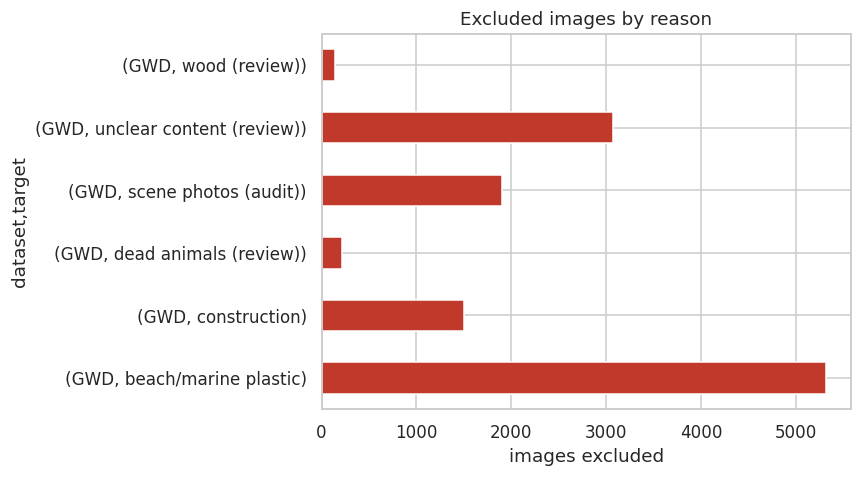

In [5]:
# ============================================================
# CELL 5 - WHAT THE MAPPING KEEPS AND WHAT IT EXCLUDES
# ============================================================
# WHAT: Count kept, excluded (by reason) and unmapped images per source, and the kept images
#       per class and source. Build `pool`, the table of images that continue to Section 3.
# WHY:  Exclusions can remove a large share of a source. Seeing the numbers shows whether a
#       class (for example `special`) comes mostly from one source, and flags unmapped labels,
#       which must be handled before training.
# HOW:  crosstab on source x decision and class x source. Unreadable files never enter `pool`.
# ------------------------------------------------------------------------------------

new_inv["outcome"] = np.where(new_inv["decision"] == "keep", "kept",
                              np.where(new_inv["decision"] == "excluded", "excluded: " + new_inv["target"], "UNMAPPED"))
display(pd.crosstab(new_inv["outcome"], new_inv["source"], margins=True, margins_name="total"))

pool = new_inv[(new_inv["decision"] == "keep") & new_inv["readable"]].reset_index(drop=True)
print(f"Images entering Section 3: {len(pool):,}")
display(pd.crosstab(pool["final_class"], pool["dataset"], margins=True, margins_name="total"))
if (new_inv["decision"] == "unmapped").any():
    print("UNMAPPED categories (add a rule in Cell 4, then re-run):",
          sorted(new_inv.loc[new_inv["decision"] == "unmapped", "category"].unique()))

ex = new_inv[new_inv["decision"] == "excluded"].groupby(["dataset", "target"]).size().rename("images")
if len(ex):
    ex.plot(kind="barh", figsize=(8, 0.5 * len(ex) + 1.5), color="#c0392b")
    plt.xlabel("images excluded"); plt.title("Excluded images by reason"); plt.tight_layout(); plt.show()

**Finding:** 82,286 of 94,439 images were kept and mapped (82,282 after 4 unreadable ones), with 0 unmapped. Excluded: beach/marine plastic 5,319 (nine `plastics` subclasses, all beach or shoreline scenes in the grids), scene photos 1,906 (`misc_trash/garbage` 879 and `rubber_polymer/rope` 1,027), construction 1,497 (cement, ceramic materials, scrap), Others_Unique 3,074 (beach scenes), `animal_dead_body` 215 (dead fish) and Wood 142 (no train images). `construction/porcelin` (791 plates and bowls) was mapped to `general`, as ceramics were in 2.0. No rule matched the wrong thing in the real folders. Medical items were mapped by subclass: 1,901 images to `general` (bandages, diapers, gloves, masks) and 3,246 to `special` (medicines, syringes, thermometers, pesticide bottles); HF light bulbs (2,136) went to `special`. `special` is fed mostly by new data (15,282 images against 995 in 2.0: GWD 8,738, HF 6,544); `general` is fed by GWD alone (4,954, none from HF); `textile` comes from GWD (7,319) and HF (7,292), though almost all of HF's share turns out to be copies (Section 3).

<a id="section-3"></a>
## Section 3: Exact & Perceptual-Hash Deduplication

**Goal:** Remove copies, in three steps. (a) Byte-identical files inside the new sources. (b) A visual fingerprint of every new image and every 2.0 image. (c) Near-duplicate pairs, verified pixel by pixel, between new and 2.0 images (new copies of anything already in 2.0 are dropped) and between new images (one copy kept).

GWD is itself a merge of 19 datasets that include RealWaste and the Garbage Dataset, which are also in 2.0, so a large overlap is expected.

In [6]:
# ============================================================
# CELL 6 - EXACT DUPLICATES INSIDE THE NEW SOURCES
# ============================================================
# WHAT: Find byte-identical files among the images that passed Section 2, show which sources
#       share them and whether the same file carries different classes, then keep one copy.
# WHY:  Identical files in two sources (or in GWD's own train/val/test folders) would be counted
#       twice and could land on both sides of a split. If two identical files carry different
#       classes, at least one mapping is wrong, so the group is dropped.
# HOW:  Two identical files have the same byte size, so only files whose size collides are
#       hashed with MD5. The 2.0 images cannot be compared byte for byte: they were re-saved as
#       224x224 JPEGs, so 2.0 is compared by fingerprint in Cells 7 to 9.
# ------------------------------------------------------------------------------------

cand = pool[pool.duplicated("bytes", keep=False)].copy()
print(f"Files sharing a byte size with another file: {len(cand):,} (these get hashed)")
cand["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in tqdm(cand["path"], desc="MD5")]

dups = cand[cand.duplicated("md5", keep=False)]
groups = dups.groupby("md5").agg(files=("path", "count"),
                                 sources=("source", lambda s: " + ".join(sorted(set(s)))),
                                 classes=("final_class", lambda s: " / ".join(sorted(set(s)))))
print(f"Exact-duplicate groups: {len(groups):,}  |  files involved: {len(dups):,}")
display(groups["sources"].value_counts().rename("groups").to_frame())
conflict_md5 = set(groups.index[groups["classes"].str.contains("/")])
print(f"Groups where the same file carries different classes: {len(conflict_md5):,}")
display(groups[groups["classes"].str.contains("/")].head(10))

PRIORITY = {"gwd-all": 0, "gwd-train": 0, "gwd-val": 1, "gwd-test": 2, "hf-train": 3, "hf-test": 4}
pool["prio"] = pool["source"].map(PRIORITY)
pool = pool.merge(cand[["path", "md5"]], on="path", how="left")
pool["status"] = "kept"
in_conflict = pool["md5"].isin(conflict_md5)
pool.loc[in_conflict, "status"] = "exact duplicate with conflicting class"
rest = pool[~in_conflict & pool["md5"].notna()].sort_values("prio")
extra = rest[rest.duplicated("md5", keep="first")].index
pool.loc[extra, "status"] = "exact duplicate"
print("\nAfter exact deduplication:")
display(pool["status"].value_counts().rename("images").to_frame())
pool1 = pool[pool["status"] == "kept"].reset_index(drop=True)
print(f"Images continuing: {len(pool1):,}")

Files sharing a byte size with another file: 46,088 (these get hashed)


MD5: 100%|██████████| 46088/46088 [05:43<00:00, 134.16it/s] 


Exact-duplicate groups: 14,694  |  files involved: 29,390


,groups
sources,
gwd-train + hf-train,9324
gwd-train + hf-test,2392
gwd-test + hf-train,1192
gwd-val + hf-train,1162
gwd-val + hf-test,337
gwd-test + hf-test,278
gwd-train,8
gwd-train + gwd-val + hf-train,1


Groups where the same file carries different classes: 12


,files,sources,classes
md5,,,
0b047234bffebd3f06dd004b83313be7,2,gwd-train + hf-test,paper_card / plastic
219ff53e0d5847b71dc42908205221d5,2,gwd-train,metal / plastic
322c861042a26edfc0afa5335a0a27bc,2,gwd-train,plastic / special
3792b2a3b47a908bd8eb4508e0295e86,2,gwd-test + hf-test,paper_card / plastic
67a09ccfc118f49431fe36243f54a259,2,gwd-train,metal / plastic
70df08c3ce6d55e25df4edbbe45e5fe3,3,gwd-train + gwd-val + hf-train,glass / metal
71524ef327d1cd6cb6780f0e2aeffd0f,2,gwd-train,glass / metal
7265e61695689fed605bbf6835c76591,2,gwd-train,metal / plastic
8fcb6edeebed41eb29cb5b02d734818a,2,gwd-train,glass / plastic



After exact deduplication:


,images
status,
kept,67574
exact duplicate,14682
exact duplicate with conflicting class,26


Images continuing: 67,574


In [7]:
# ============================================================
# CELL 7 - VISUAL FINGERPRINT OF EVERY 2.0 IMAGE AND EVERY NEW IMAGE
# ============================================================
# WHAT: For each image compute a 64-bit difference hash (dHash), a 32x32 grey thumbnail for
#       pixel checks, and the image properties Section 6 needs (colour, brightness, clutter,
#       border plainness). Save the hashes (the thumbnails are large and only needed here).
# WHY:  Re-saved, resized or recompressed copies have different bytes but the same picture. All
#       images, old and new, must be seen in the SAME form: the 2.0 files are centre-cropped
#       squares, so each new image is centre-cropped to a square before hashing. Otherwise a
#       wide GD photo would never match its 2.0 copy. One pass over each file does both jobs,
#       because decoding is the slow part.
# HOW:  Open (img.draft makes JPEG decoding much faster), centre-crop the square, shrink to
#       64x64. The dHash records, for a 9x8 grey version, whether each pixel is brighter than its
#       right-hand neighbour. Edge density (clutter) and brightness follow the 2.0 definitions.
#       Border plainness = standard deviation of grey values in the outer 8-pixel ring. The share of pure-black pixels in
#       the ring and in the centre is kept too (black_ring, black_core), for the black-padding check in Section 6. No EXIF
#       rotation is applied, matching how 2.0 standardised its images. A failed read gives an
#       all-zero hash and is flagged.
# ------------------------------------------------------------------------------------

LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)
RING = np.ones((64, 64), dtype=bool); RING[8:-8, 8:-8] = False

def fingerprint(path):
    try:
        with Image.open(path) as im:
            im.draft("RGB", (128, 128))
            im = im.convert("RGB")
            w, h = im.size
            s = min(w, h)
            left, top = (w - s) // 2, (h - s) // 2
            sq = im.crop((left, top, left + s, top + s)).resize((64, 64), Image.LANCZOS)
    except Exception:
        return np.zeros(64, np.uint8), np.zeros(1024, np.float16), [np.nan] * 10 + [False]
    g9 = np.asarray(sq.convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bits = (g9[:, 1:] > g9[:, :-1]).ravel().astype(np.uint8)
    t = np.asarray(sq.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel()
    t = t - t.mean(); n = np.linalg.norm(t)
    t = (t / n if n > 0 else t).astype(np.float16)
    a = np.asarray(sq, dtype=np.float32)
    gray = a @ LUMA
    edge = np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean()
    black = a.max(axis=2) <= 12                      # pure black: rotation padding or letterbox bars
    props = [a[..., 0].mean(), a[..., 1].mean(), a[..., 2].mean(), gray.mean(), edge,
             gray[RING].std(), gray[RING].mean(), gray.std(), black[RING].mean(), black[~RING].mean(), True]
    return bits, t, props

PROP_COLS = ["mean_r", "mean_g", "mean_b", "brightness", "edge_density", "border_std", "border_mean", "gray_std", "black_ring", "black_core", "fp_ok"]

# one table for both worlds: rows 0..n2-1 are the 2.0 images, the rest are the new images
n2 = len(v2)
allimg = pd.concat([
    pd.DataFrame({"origin": "v2", "dataset": "2.0", "source": "2.0-" + v2["split"], "final_class": v2["final_class"],
                  "category": v2["label"], "path": v2["abs_path"]}),
    pd.DataFrame({"origin": "new", "dataset": pool1["dataset"], "source": pool1["source"], "final_class": pool1["final_class"],
                  "category": pool1["category"], "path": pool1["path"]}),
], ignore_index=True)

with ThreadPoolExecutor(max_workers=4) as ex:
    res = list(tqdm(ex.map(fingerprint, allimg["path"]), total=len(allimg), desc="Fingerprints"))
DH = np.stack([r[0] for r in res])
TH = np.stack([r[1] for r in res])
PROPS = pd.DataFrame([r[2] for r in res], columns=PROP_COLS)
allimg = pd.concat([allimg, PROPS], axis=1)
allimg["flat"] = allimg["gray_std"] < 3          # almost one colour: its hash says nothing

np.savez_compressed(WORK / "new_dhash.npz", dhash=DH)
allimg.drop(columns=["path"]).to_csv(WORK / "image_properties.csv", index=False)
print(f"Fingerprinted {len(allimg):,} images  |  failed reads: {int((~allimg['fp_ok'].astype(bool)).sum())}"
      f"  |  flat images (not matched): {int(allimg['flat'].sum())}")
display(allimg.groupby("source").size().rename("images").to_frame())

Fingerprints: 100%|██████████| 81998/81998 [08:23<00:00, 162.85it/s]


Fingerprinted 81,998 images  |  failed reads: 6  |  flat images (not matched): 15


,images
source,
2.0-test,2164
2.0-train,10096
2.0-val,2164
gwd-test,5444
gwd-train,42570
gwd-val,5406
hf-test,2569
hf-train,11585


In [8]:
# ============================================================
# CELL 8 - FIND AND VERIFY NEAR-DUPLICATE PAIRS (NEW VS 2.0, NEW VS NEW)
# ============================================================
# WHAT: Compare the hash of every new image with every 2.0 image and every other new image,
#       keep pairs within CAND_BITS, and verify each pair by comparing the grey thumbnails.
# WHY:  A hash alone is dominated by plain backgrounds: in 2.0, 3,139 of 5,728 pairs at 4 bits
#       were different products on white. A real copy matches pixel for pixel. We use the 2.0
#       settings (candidates up to 6 bits, thumbnail correlation >= 0.97) so 3.0 and 2.0 treat
#       duplicates the same way. The aspect-ratio check of 2.0 is not needed because both sides
#       are already the same centre-cropped square.
# HOW:  Hamming distance = bits(a) + bits(b) - 2 * (a . b), so one matrix product per chunk gives
#       all distances. Each pair is counted once: new image i is paired with every 2.0 image and
#       with later new images only. Thumbnails are mean-centred and normalised, so their dot
#       product is the correlation. Flat and failed images are skipped.
# ------------------------------------------------------------------------------------

CAND_BITS, CORR_MIN = 6, 0.97

usable = (allimg["fp_ok"].astype(bool) & ~allimg["flat"]).values
Hf = DH.astype(np.float32)
pop = Hf.sum(1)
N = len(allimg)
pi, pj, pd_ = [], [], []
for s in tqdm(range(n2, N, 500), desc="Comparing hashes"):
    e = min(s + 500, N)
    d = np.rint(pop[s:e, None] + pop[None, :] - 2 * (Hf[s:e] @ Hf.T))
    ii, jj = np.nonzero(d <= CAND_BITS)
    gi = ii + s
    keep = usable[gi] & usable[jj] & ((jj < n2) | (jj > gi))
    pi.append(gi[keep]); pj.append(jj[keep]); pd_.append(d[ii[keep], jj[keep]])
cp = pd.DataFrame({"i": np.concatenate(pi), "j": np.concatenate(pj), "d": np.concatenate(pd_).astype(int)})

corr = np.empty(len(cp), dtype=np.float32)
for s in range(0, len(cp), 50000):
    a = TH[cp["i"].values[s:s + 50000]].astype(np.float32)
    b = TH[cp["j"].values[s:s + 50000]].astype(np.float32)
    corr[s:s + 50000] = np.einsum("ij,ij->i", a, b)
cp["corr"] = corr
cp["verified"] = cp["corr"] >= CORR_MIN
cp["kind"] = np.where(cp["j"] < n2, "new vs 2.0", "new vs new")

print(f"Candidate pairs (<= {CAND_BITS} bits): {len(cp):,}  |  verified: {int(cp['verified'].sum()):,}")
display(cp.groupby(["kind", "d"])["verified"].agg(candidates="size", verified="sum"))
vp = cp[cp["verified"]]
cls_arr = allimg["final_class"].values
print(f"Verified pairs with DIFFERENT classes: {int((cls_arr[vp['i']] != cls_arr[vp['j']]).sum()):,}")
display(pd.Series([" + ".join(sorted({allimg.at[a, 'source'], allimg.at[b, 'source']})) for a, b in zip(vp["i"], vp["j"])]).value_counts().rename("pairs").head(15).to_frame())

Comparing hashes: 100%|██████████| 136/136 [00:36<00:00,  3.77it/s]


Candidate pairs (<= 6 bits): 109,717  |  verified: 16,855


candidates  verified
kind       d                      
new vs 2.0 0        9788      9448
           1        4471      3518
           2        2850       923
           3        3385       291
           4        5377        77
           5        8460        34
           6       13517        16
new vs new 0        1428       904
           1        2077       670
           2        3455       426
           3        5376       262
           4        9067       152
           5       15282        87
           6       25184        47

Verified pairs with DIFFERENT classes: 8


,pairs
2.0-train + gwd-train,7645
2.0-test + gwd-train,1609
2.0-val + gwd-train,1595
gwd-train,1190
2.0-train + gwd-test,1010
2.0-train + gwd-val,1006
gwd-test + gwd-train,334
gwd-train + hf-train,332
gwd-train + gwd-val,317
2.0-train + hf-train,295


Deduplication outcome for the new images:


source,gwd-test,gwd-train,gwd-val,hf-test,hf-train,total
status,,,,,,
already in 2.0,1449,10827,1445,113,438,14272
copy of another new image,250,791,202,85,170,1498
kept,3745,30945,3759,2371,10977,51797
mixed-class duplicate group,0,7,0,0,0,7
total,5444,42570,5406,2569,11585,67574


Share of each source that is already in 2.0:


,% already in 2.0
source,
gwd-test,26.6
gwd-train,25.4
gwd-val,26.7
hf-test,4.4
hf-train,3.8


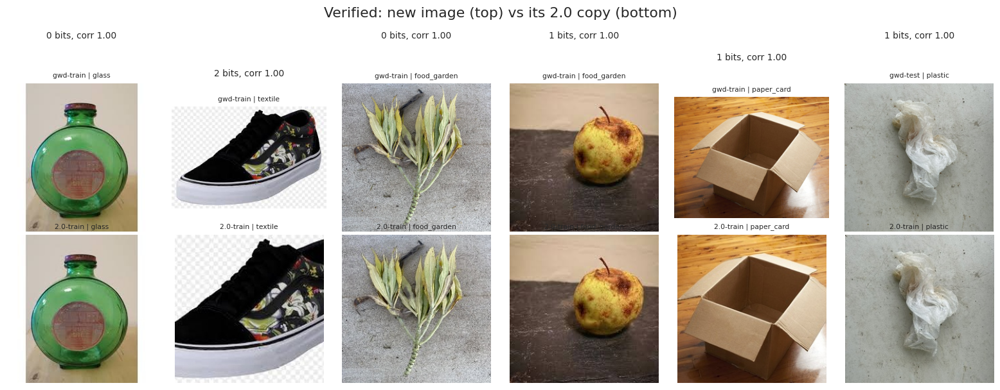

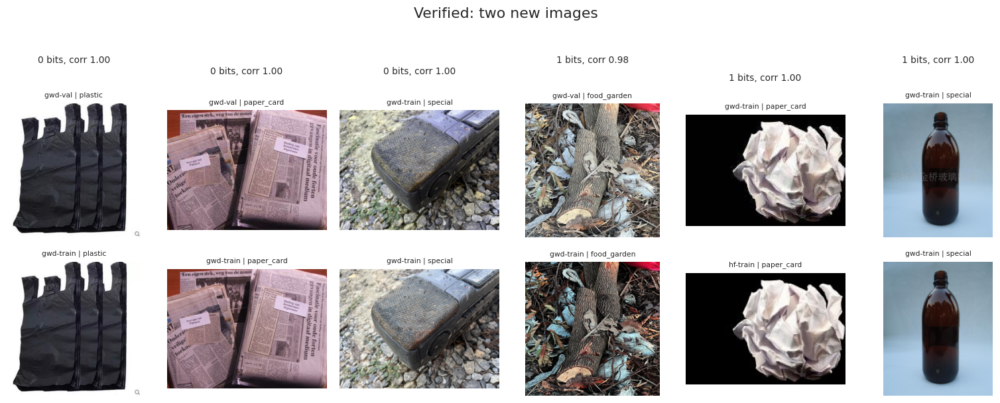

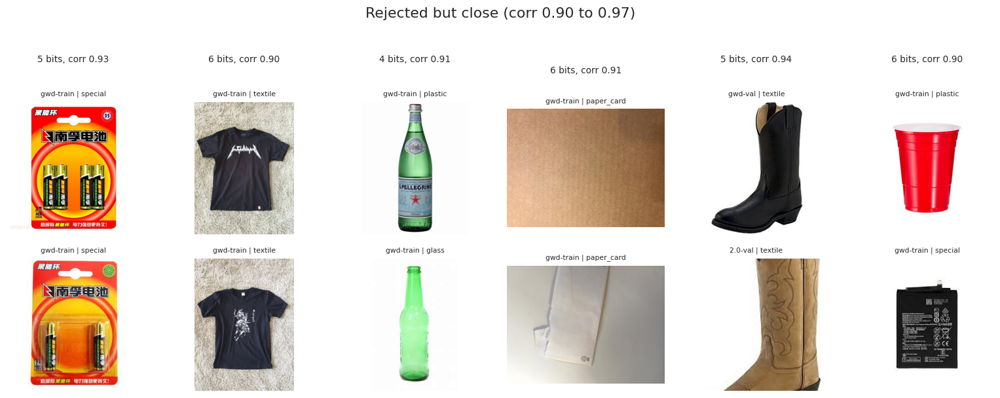

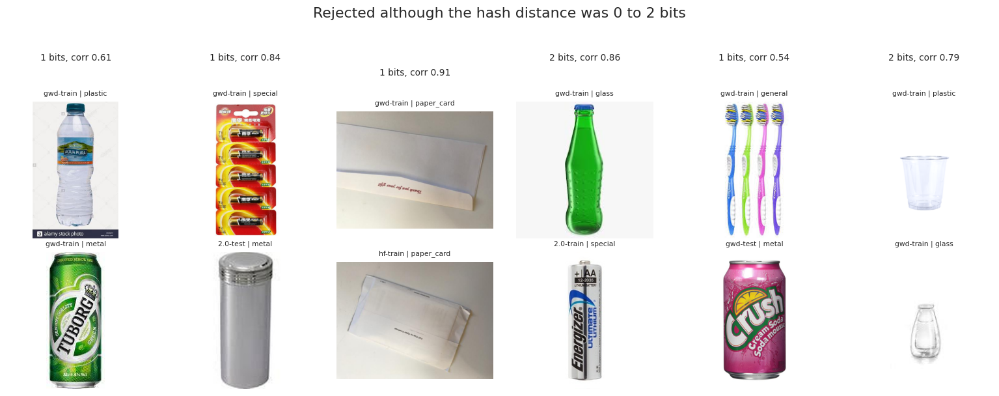


New images continuing to Section 4: 51,797 of 67,574


In [9]:
# ============================================================
# CELL 9 - DROP COPIES OF 2.0, KEEP ONE OF EACH NEW GROUP, AND LOOK AT THE PAIRS
# ============================================================
# WHAT: Mark every new image as kept, "already in 2.0", a copy inside the new sources, or in a
#       group whose copies carry different classes. Save the report and show example pairs.
# WHY:  The brief is to drop new copies of anything already in 2.0, so 2.0 always wins. Among new
#       images only one copy survives (GWD before Hugging Face), and a group with two different
#       classes is dropped because one of the labels must be wrong. Viewing real pairs, including
#       rejected ones, is how we judge CORR_MIN by eye.
# HOW:  Union-find over the verified pairs. A new image joins "already in 2.0" if its group
#       contains a 2.0 image. For the rest, sort by priority and keep the first of each group.
#       The viewer shows the top row as the new image and the bottom row as its match.
# ------------------------------------------------------------------------------------

parent = np.arange(N)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in vp[["i", "j"]].itertuples(index=False):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
allimg["group"] = [find(i) for i in range(N)]

new_rows = allimg[allimg["origin"] == "new"].copy()
v2_groups = set(allimg.loc[:n2 - 1, "group"])
mixed = allimg.groupby("group")["final_class"].nunique()
mixed_groups = set(mixed.index[mixed > 1])

new_rows["status"] = "kept"
new_rows.loc[new_rows["group"].isin(mixed_groups), "status"] = "mixed-class duplicate group"
new_rows.loc[new_rows["group"].isin(v2_groups), "status"] = "already in 2.0"
new_rows["prio"] = new_rows["source"].map(PRIORITY)
live = new_rows[new_rows["status"] == "kept"].sort_values("prio")
new_rows.loc[live[live.duplicated("group", keep="first")].index, "status"] = "copy of another new image"

new_rows["matches_v2_split"] = ""
for i, j in zip(vp.loc[vp["j"] < n2, "i"], vp.loc[vp["j"] < n2, "j"]):
    s = allimg.at[j, "source"].replace("2.0-", "")
    cur = new_rows.at[i, "matches_v2_split"]
    new_rows.at[i, "matches_v2_split"] = s if not cur else ",".join(sorted(set(cur.split(",")) | {s}))

report = pool1[["source", "final_class", "category", "sub", "path"]].copy()
report["status"] = new_rows["status"].values
report["matches_v2_split"] = new_rows["matches_v2_split"].values
report.to_csv(WORK / "dedup_report.csv", index=False)

print("Deduplication outcome for the new images:")
display(pd.crosstab(report["status"], report["source"], margins=True, margins_name="total"))
print("Share of each source that is already in 2.0:")
display((pd.crosstab(report["source"], report["status"] == "already in 2.0", normalize="index")[True] * 100).round(1).rename("% already in 2.0").to_frame())

def show_cand(sel, title, k=6):
    if sel.empty:
        print(f"{title}: none"); return
    sel = sel.sample(min(k, len(sel)), random_state=SEED)
    fig, axes = plt.subplots(2, len(sel), figsize=(len(sel) * 2.4, 5.4), squeeze=False)
    for c, (_, r) in enumerate(sel.iterrows()):
        for rr, idx in enumerate((int(r["i"]), int(r["j"]))):
            ax = axes[rr, c]; ax.axis("off")
            with Image.open(allimg.at[idx, "path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{allimg.at[idx, 'source']} | {allimg.at[idx, 'final_class']}", fontsize=7)
        axes[0, c].text(0.5, 1.30, f"{int(r['d'])} bits, corr {r['corr']:.2f}", transform=axes[0, c].transAxes, ha="center", fontsize=9)
    plt.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

show_cand(cp[cp["verified"] & (cp["kind"] == "new vs 2.0")], "Verified: new image (top) vs its 2.0 copy (bottom)")
show_cand(cp[cp["verified"] & (cp["kind"] == "new vs new")], "Verified: two new images")
show_cand(cp[~cp["verified"] & (cp["corr"] >= 0.90)], "Rejected but close (corr 0.90 to 0.97)")
show_cand(cp[~cp["verified"] & (cp["d"] <= 2)], "Rejected although the hash distance was 0 to 2 bits")

pool2 = pool1[(report["status"] == "kept").values].reset_index(drop=True)
print(f"\nNew images continuing to Section 4: {len(pool2):,} of {len(pool1):,}")

**Finding:** Funnel: 82,282 images after mapping, 67,574 after exact duplicates (14,682 copies plus 26 files in 12 groups where the same file carries two classes), 51,797 after dropping 14,272 copies of 2.0, 1,498 copies inside the new sources and 7 mixed-class near-duplicates. About 25.7% of GWD is already in 2.0 (13,721 of 53,420; it contains RealWaste and GD) and about 3.9% of HF (551 of 14,154). Against GWD, HF is the bigger problem: about half of HF (14,686 of 28,840 images) is byte-identical to a GWD image, so HF adds only 13,348 images that GWD does not have, and almost all of its `clothes` class goes (7,292 raw, 106 kept). The verification works as intended: of the new-vs-2.0 candidate pairs, 9,448 of 9,788 at 0 bits are verified copies, but only 16 of 13,517 at 6 bits, so the correlation test rejects look-alikes that the hash alone would accept (the viewers on run 1 showed copies at other resolutions or crops, even a greyscale copy of a colour photo, and look-alikes such as different jeans and bottles for the rejected pairs), and CORR_MIN = 0.97 looks right. The mixed-class groups point to label noise inside the sources: 12 exact groups hold the same file under two classes (glass/metal, metal/plastic, paper_card/plastic, plastic/special, glass/plastic) and 8 verified near-duplicate pairs carry two classes; all were dropped. In run 1, 397 exact groups were one file filed under both GWD `plastics` and `misc_trash/garbage`; they disappear here because `garbage` is now excluded, which confirms that GWD filed the same photos in both.

<a id="section-4"></a>
## Section 4: Leakage Check: 2.0 Test Set & Real Photos

**Goal:** Make sure no new training image is a copy of a 2.0 test image or of one of our 24 real photos. Otherwise the two yardsticks used in the final comparison (the frozen 2.0 test set and the real photos) would be inflated.

New images that were copies of 2.0 images: 14,272


,copies of 2.0 images in this split
train,10024
val,2132
test,2131



Real photos found: 24


,reference images,candidates (<= 10 bits),loose matches (corr >= 0.9),strict matches (corr >= 0.97)
reference,,,,
2.0 test set,2164,22252,248,2
real photos,24,29,0,0
real photos vs ALL of 2.0,24,11,0,0



Surviving new images: 51,797  |  failed or flat: 19  |  loose matches: 222  |  dropped now: 241


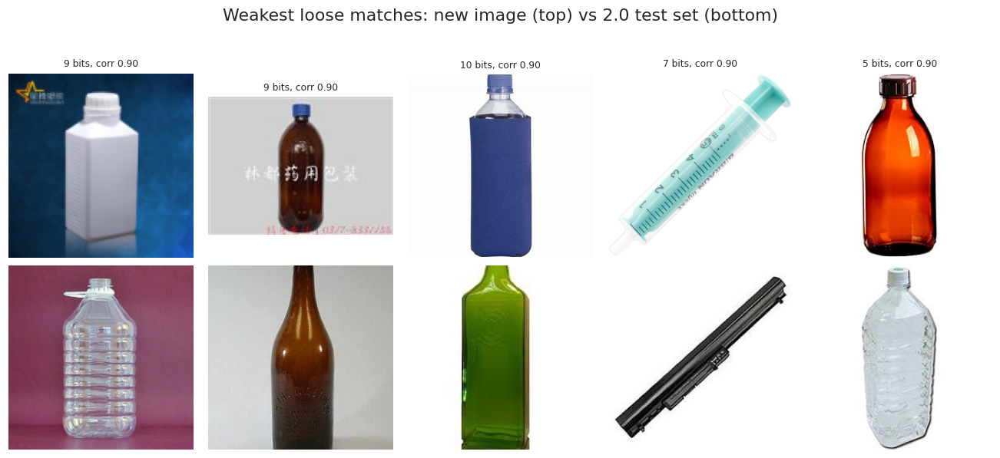

real photos: no loose matches
New images continuing to Section 5: 51,556


In [10]:
# ============================================================
# CELL 10 - HOW MUCH WOULD HAVE LEAKED, AND A LOOSER SECOND CHECK
# ============================================================
# WHAT: (a) Count the new images that were verified copies of 2.0 train, val or test images
#       (dropped in Section 3). (b) Find our real photos, fingerprint them, and compare every
#       surviving new image with the 2.0 test set and the photos at a LOOSER setting than
#       Section 3. Only pairs that pass the loose rule are kept in memory. (c) Drop what is left of failed or flat images and any loose match.
# WHY:  (a) shows the size of the problem: every copy of a test image that had stayed in training
#       is an answer the model has already seen. (b) Section 3 used a strict rule so that real
#       but different photos are kept; for the two test sets we prefer to lose a few extra
#       images than to leak one, so the rule is relaxed to 10 bits and correlation 0.90.
#       (c) Failed or flat images cannot be compared, so their leakage cannot be ruled out, and
#       they carry no information anyway.
# HOW:  The photos are the images under /kaggle/input whose file name starts with a class name and
#       an underscore (as in the real-photo notebooks), outside the 2.0, GWD and Hugging Face
#       folders. They are fingerprinted like all other images (no EXIF rotation, which is
#       harmless here: a catalogue copy of a phone photo is not expected anyway).
# ------------------------------------------------------------------------------------

# (a) copies of 2.0 images found in Section 3
hit = report[report["status"] == "already in 2.0"]
print(f"New images that were copies of 2.0 images: {len(hit):,}")
split_hits = pd.Series({s: int(hit["matches_v2_split"].str.contains(s).sum()) for s in ["train", "val", "test"]})
display(split_hits.rename("copies of 2.0 images in this split").to_frame())

# (b) real photos
skip_dirs = [V2] + list(GWD.values())
def label_of(path):
    stem = path.stem.lower()
    for c in sorted(CLASSES, key=len, reverse=True):
        if stem.startswith(c + "_"):
            return c
    return None
photo_paths = sorted(p for p in INPUT.rglob("*")
                     if p.suffix.lower() in IMAGE_EXTS and not any(p.is_relative_to(d) for d in skip_dirs)
                     and label_of(p))
assert photo_paths, "No real photos found: attach your real-photo dataset (file names class_item_number.jpg)"
print(f"\nReal photos found: {len(photo_paths)}")
pres = [fingerprint(p) for p in photo_paths]
PH_DH = np.stack([r[0] for r in pres]).astype(np.float32)
PH_TH = np.stack([r[1] for r in pres]).astype(np.float32)
photo_props = pd.DataFrame([r[2] for r in pres], columns=PROP_COLS)

survivors = np.where((allimg["origin"] == "new").values)[0][(report["status"] == "kept").values]
LOOSE_BITS, LOOSE_CORR = 10, 0.90
test_idx = np.where((allimg["origin"] == "v2") & (allimg["source"] == "2.0-test"))[0]
refs = {"2.0 test set": (DH[test_idx].astype(np.float32), TH[test_idx].astype(np.float32)),
        "real photos": (PH_DH, PH_TH)}

def loose_matches(ref_h, ref_t):
    """Candidates within LOOSE_BITS: their number, and the pairs (survivor, reference, bits, corr) with corr >= LOOSE_CORR."""
    cols, n_cand = {"surv": [np.empty(0, int)], "ref": [np.empty(0, int)], "bits": [np.empty(0)], "corr": [np.empty(0)]}, 0
    sh = DH[survivors].astype(np.float32)
    sp = sh.sum(1); rp = ref_h.sum(1)
    for s in range(0, len(sh), 2000):
        d = np.rint(sp[s:s + 2000, None] + rp[None, :] - 2 * (sh[s:s + 2000] @ ref_h.T))
        ii, jj = np.nonzero(d <= LOOSE_BITS)
        n_cand += len(ii)
        for t in range(0, len(ii), 20000):
            a, b = ii[t:t + 20000], jj[t:t + 20000]
            c = np.einsum("ij,ij->i", TH[survivors[a + s]].astype(np.float32), ref_t[b])
            ok = c >= LOOSE_CORR
            for name, vals in [("surv", a[ok] + s), ("ref", b[ok]), ("bits", d[a[ok], b[ok]]), ("corr", c[ok])]:
                cols[name].append(vals)
    return n_cand, pd.DataFrame({k: np.concatenate(v) for k, v in cols.items()})

leak_rows, leak_drop = [], set()
found = {}
for name, (rh, rt) in refs.items():
    n_cand, loose = loose_matches(rh, rt)
    found[name] = loose
    leak_rows.append({"reference": name, "reference images": len(rh),
                      f"candidates (<= {LOOSE_BITS} bits)": n_cand, f"loose matches (corr >= {LOOSE_CORR})": len(loose),
                      "strict matches (corr >= 0.97)": int((loose["corr"] >= CORR_MIN).sum())})
    leak_drop |= set(loose["surv"])
# the real photos against ALL of 2.0 (a sanity check that the photos are not catalogue images)
m2 = np.rint(PH_DH.sum(1)[:, None] + DH[:n2].astype(np.float32).sum(1)[None, :] - 2 * (PH_DH @ DH[:n2].astype(np.float32).T))
pi_, pj_ = np.nonzero(m2 <= LOOSE_BITS)
c2 = np.einsum("ij,ij->i", PH_TH[pi_], TH[pj_].astype(np.float32))
leak_rows.append({"reference": "real photos vs ALL of 2.0", "reference images": len(PH_DH),
                  f"candidates (<= {LOOSE_BITS} bits)": len(pi_), f"loose matches (corr >= {LOOSE_CORR})": int((c2 >= LOOSE_CORR).sum()),
                  "strict matches (corr >= 0.97)": int((c2 >= CORR_MIN).sum())})
leakage = pd.DataFrame(leak_rows).set_index("reference")
display(leakage)

# (c) drop failed / flat images and every loose match
bad_fp = ~usable[survivors]
drop = bad_fp | np.isin(np.arange(len(survivors)), list(leak_drop))
print(f"\nSurviving new images: {len(survivors):,}  |  failed or flat: {int(bad_fp.sum())}  |  loose matches: {len(leak_drop)}"
      f"  |  dropped now: {int(drop.sum())}")
leakage.assign(dropped_failed_or_flat=int(bad_fp.sum()), dropped_loose_matches=len(leak_drop)).to_csv(WORK / "leakage_report.csv")

# the closest remaining pairs, to judge the loose rule by eye
def show_leak(name, k=5):
    m = found[name].sort_values("corr").head(k)
    if m.empty:
        print(f"{name}: no loose matches"); return
    fig, axes = plt.subplots(2, len(m), figsize=(len(m) * 2.4, 5.4), squeeze=False)
    for c, (_, r) in enumerate(m.iterrows()):
        a = int(survivors[int(r["surv"])])
        ref_path = allimg.at[test_idx[int(r["ref"])], "path"] if name == "2.0 test set" else str(photo_paths[int(r["ref"])])
        for rr, p in enumerate((allimg.at[a, "path"], ref_path)):
            axes[rr, c].axis("off")
            with Image.open(p) as im:
                axes[rr, c].imshow(ImageOps.exif_transpose(im).convert("RGB"))
        axes[0, c].set_title(f"{int(r['bits'])} bits, corr {r['corr']:.2f}", fontsize=8)
    plt.suptitle(f"Weakest loose matches: new image (top) vs {name} (bottom)", y=1.02); plt.tight_layout(); plt.show()
show_leak("2.0 test set"); show_leak("real photos")

pool3 = pool2[~drop].reset_index(drop=True)
print(f"New images continuing to Section 5: {len(pool3):,}")

**Finding:** 2,131 new images matched a 2.0 test image (against 10,024 matching 2.0 train and 2,132 matching 2.0 val images), so the 2.0 test set would have been largely present in the training data had they been kept; they were removed in Section 3. The looser check against the 2.0 test set found 248 loose matches (22,252 candidates), of which 2 are strict; with 19 failed or flat images, 241 more new images were dropped (222 loose matches). For the 24 real photos there are 29 candidates, 0 loose matches and 0 strict matches, also against all of 2.0 (11 candidates, 0 matches), as expected for photos we took. The weakest loose matches in the viewer (checked on run 1; the rule is unchanged) are look-alikes such as different bottles and a syringe against a laptop battery, so the loose rule is conservative and cost 222 images (0.4% of the new data). After this section no surviving new image matches the 2.0 test set or a real photo at the checked settings (at most 10 hash bits and correlation 0.90 or more).

<a id="section-5"></a>
## Section 5: Class Balance Before and After

**Goal:** Show the class sizes of 2.0 (before), what the new sources add, and the combined sizes (after). If one class would dominate, cap the new images only, never the 2.0 images.

,2.0 (before),"new, available","new, kept after cap",3.0 (after),new share of 3.0
final_class,,,,,
food_garden,1883,5479,5479,7362,0.74
general,1440,3434,3434,4874,0.70
glass,1783,3854,3854,5637,0.68
metal,1876,6145,6145,8021,0.77
paper_card,2161,7354,7354,9515,0.77
plastic,2059,6859,6859,8918,0.77
special,995,12962,12962,13957,0.93
textile,2227,5469,5469,7696,0.71


Imbalance ratio (largest / smallest), 2.0 (before): 2.24x
Imbalance ratio (largest / smallest), new, available: 3.77x
Imbalance ratio (largest / smallest), 3.0 (after): 2.86x
Cap per class (total): 14,622


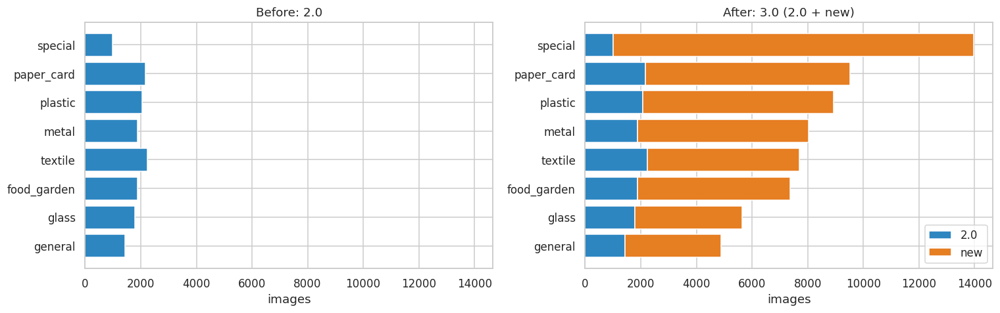

Kept new images per class and dataset:


dataset,GWD,HF,total
final_class,,,
food_garden,4402,1077,5479
general,3434,0,3434
glass,2817,1037,3854
metal,3820,2325,6145
paper_card,5713,1641,7354
plastic,5187,1672,6859
special,7488,5474,12962
textile,5363,106,5469
total,38224,13332,51556


In [11]:
# ============================================================
# CELL 11 - CLASS BALANCE: 2.0 ALONE, NEW IMAGES, AND BOTH TOGETHER
# ============================================================
# WHAT: Tabulate images per class for 2.0, for the new images that survived Sections 2 to 4, and
#       for the sum. Cap the new images with RATIO_MAX, then chart before and after.
# WHY:  GWD's plastics alone are 24,984 of 89,807 images, so the new data is far less balanced
#       than 2.0 (2.24x). A model trained on a raw merge would see mostly plastic, and the
#       new sources would swamp the 2.0 images that look most like ours. The cap keeps the
#       largest class at no more than RATIO_MAX times the smallest class of the merged set.
#       Only new images are removed, so 2.0 stays complete.
# HOW:  Smallest merged class size x RATIO_MAX = maximum total per class. Each class may add
#       (maximum - its 2.0 size) new images, chosen at random with a fixed seed so each source
#       keeps its share on average. RATIO_MAX = None switches the cap off.
# ------------------------------------------------------------------------------------

RATIO_MAX = 3.0

n_v2 = v2["final_class"].value_counts().reindex(CLASSES)
n_new = pool3["final_class"].value_counts().reindex(CLASSES).fillna(0).astype(int)
if RATIO_MAX is None:
    cap_total = np.inf
else:
    cap_total = RATIO_MAX * (n_v2 + n_new).min()
allowed = (cap_total - n_v2).clip(lower=0).clip(upper=n_new) if RATIO_MAX else n_new
shuffled = pool3.sample(frac=1, random_state=SEED)
shuffled["rank"] = shuffled.groupby("final_class").cumcount()
pool4 = shuffled[shuffled["rank"] < shuffled["final_class"].map(allowed)].drop(columns="rank").reset_index(drop=True)

bal = pd.DataFrame({"2.0 (before)": n_v2, "new, available": n_new,
                    "new, kept after cap": pool4["final_class"].value_counts().reindex(CLASSES).fillna(0).astype(int)})
bal["3.0 (after)"] = bal["2.0 (before)"] + bal["new, kept after cap"]
bal["new share of 3.0"] = (bal["new, kept after cap"] / bal["3.0 (after)"]).round(2)
display(bal)
for col in ["2.0 (before)", "new, available", "3.0 (after)"]:
    print(f"Imbalance ratio (largest / smallest), {col}: {bal[col].max() / bal[col].min():.2f}x")
print(f"Cap per class (total): {cap_total:,.0f}")

order = bal["3.0 (after)"].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
axes[0].barh(order, bal.loc[order, "2.0 (before)"], color="#2e86c1"); axes[0].set_title("Before: 2.0")
axes[1].barh(order, bal.loc[order, "2.0 (before)"], color="#2e86c1", label="2.0")
axes[1].barh(order, bal.loc[order, "new, kept after cap"], left=bal.loc[order, "2.0 (before)"], color="#e67e22", label="new")
axes[1].set_title("After: 3.0 (2.0 + new)"); axes[1].legend()
for ax in axes:
    ax.invert_yaxis(); ax.set_xlabel("images")
plt.tight_layout(); plt.show()

print("Kept new images per class and dataset:")
display(pd.crosstab(pool4["final_class"], pool4["dataset"], margins=True, margins_name="total"))

**Finding:** The imbalance ratio is 2.24x for 2.0, 3.77x for the new images alone and 2.86x for the full 3.0 set (before the black-padding drop in Section 8); the cap (3x the smallest class, 14,622) removed nothing. Gains in total images: `special` 995 to 13,957, `general` 1,440 to 4,874, `plastic` 2,059 to 8,918, `textile` 2,227 to 7,696. `special` and `textile` gain real images, but `special` is 93% new data and `general` 70% new, and `general` is still the smallest class. Sources: `general` is GWD only (medical 1,889, porcelain and ceramics 771, rubber 646, misc_trash 128, so it is mostly bandages, masks, gloves and plates, with little general rubbish); `textile` is 98% GWD (5,363 against 106 from HF); `special` mixes GWD (7,488) and HF (5,474); the other classes mix both. A class from one source teaches that source's style, which is why `general` and `textile` need the real-photo check.

<a id="section-6"></a>
## Section 6: Image Properties & Studio vs Real-World Backgrounds

**Goal:** Describe the new images (size, shape, file type), and measure how many are studio-style shots (plain background) compared with real-world scenes. Our target is the Pi camera and the phone, so the new data helps only if it is closer to a real scene than 2.0 was.

dataset                GWD        HF
width      count  38224.00  13332.00
           mean     765.33    918.93
           std      837.99   1065.94
           min       59.00     52.00
           25%      372.00    408.00
           50%      533.00    612.00
           75%      736.00    750.00
           max    12290.00   6898.00
height     count  38224.00  13332.00
           mean     681.88    827.95
           std      647.66    967.18
           min       69.00     40.00
           25%      311.00    328.00
           50%      533.00    408.00
           75%      650.00    640.00
           max     6793.00   7262.00
megapixels count  38224.00  13332.00
           mean       1.03      1.68
           std        2.72      3.84
           min        0.01      0.00
           25%        0.12      0.14
           50%        0.25      0.25
           75%        0.44      0.46
           max       45.85     35.20
aspect     count  38224.00  13332.00
           mean       1.13      1.24
           std        0.34      0.45
           min        0.19      0.18
           25%        0.94      0.96
           50%        1.00      1.33
           75%        1.33      1.50
           max        6.40      9.02
kb         count  38224.00  13332.00
           mean     301.33    457.84
           std      992.16   1101.45
           min        0.78      1.82
           25%       16.00     27.32
           50%       39.29     50.09
           75%      107.70    124.54
           max    12467.39  12581.11

ext,.jpeg,.jpg,.png
dataset,,,
GWD,0.014,0.954,0.032
HF,0.037,0.903,0.061


Share of images with the short side below 224 px (upscaled when standardised):


,% below 224 px
dataset,
GWD,12.6
HF,12.4


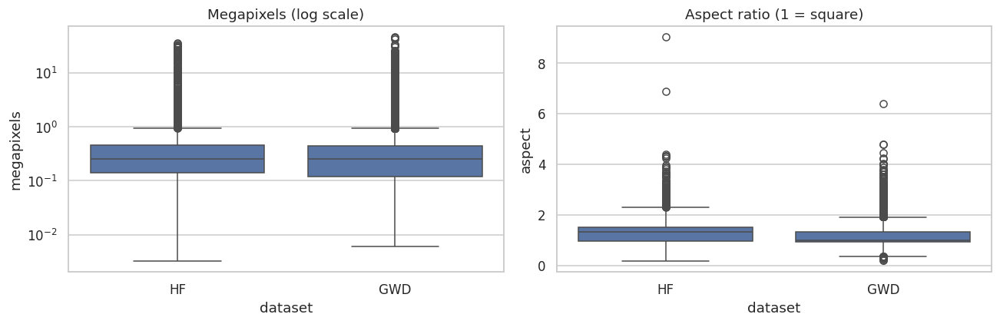

In [12]:
# ============================================================
# CELL 12 - RAW IMAGE PROPERTIES OF THE NEW IMAGES
# ============================================================
# WHAT: Show file type, size in pixels, aspect ratio and file size of the kept new images, per
#       dataset. (The 2.0 images are all 224x224 JPEG by construction, so there is nothing to compare.)
# WHY:  Different formats and sizes can act as a shortcut (2.0 Cell 4: a model could name the
#       source from format alone). Very large or very small images also tell us how much the
#       224x224 standardisation in Section 8 throws away.
# HOW:  The numbers come from the header scan in Cell 2 (nothing is decoded again). Megapixels =
#       width x height / 1e6; aspect = width / height.
# ------------------------------------------------------------------------------------

pool4["megapixels"] = pool4["width"] * pool4["height"] / 1e6
pool4["aspect"] = pool4["width"] / pool4["height"]
pool4["kb"] = pool4["bytes"] / 1024

display(pool4.groupby("dataset")[["width", "height", "megapixels", "aspect", "kb"]].describe().T.round(2))
display(pd.crosstab(pool4["dataset"], pool4["ext"], normalize="index").round(3))
print("Share of images with the short side below 224 px (upscaled when standardised):")
display((pool4.assign(small=np.minimum(pool4["width"], pool4["height"]) < 224).groupby("dataset")["small"].mean() * 100).round(1).rename("% below 224 px").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=pool4, x="dataset", y="megapixels", ax=axes[0]); axes[0].set_yscale("log"); axes[0].set_title("Megapixels (log scale)")
sns.boxplot(data=pool4, x="dataset", y="aspect", ax=axes[1]); axes[1].set_title("Aspect ratio (1 = square)")
plt.tight_layout(); plt.show()

Share of images (%) with a plain / white / dark frame:


,plain,white,dark,images
dataset,,,,
2.0,5.2,2.8,0.5,14424
GWD,3.4,2.5,0.2,38224
HF,1.6,1.1,0.1,13332
our photos,0.0,0.0,0.0,24


Plain-frame share (%) per class and dataset:


dataset,2.0,GWD,HF,our photos
final_class,,,,
food_garden,2.0,1.0,0.0,0.0
general,15.0,4.0,NaN,0.0
glass,4.0,5.0,2.0,0.0
metal,6.0,6.0,0.0,0.0
paper_card,3.0,5.0,4.0,0.0
plastic,4.0,4.0,0.0,0.0
special,12.0,3.0,2.0,0.0
textile,3.0,1.0,8.0,0.0


Median clutter (edge density) and border variation per dataset:


,edge_density,border_std,brightness
dataset,,,
2.0,16.7,30.7,156.0
GWD,22.4,43.7,145.2
HF,25.7,48.1,125.9
our photos,21.2,45.4,140.0


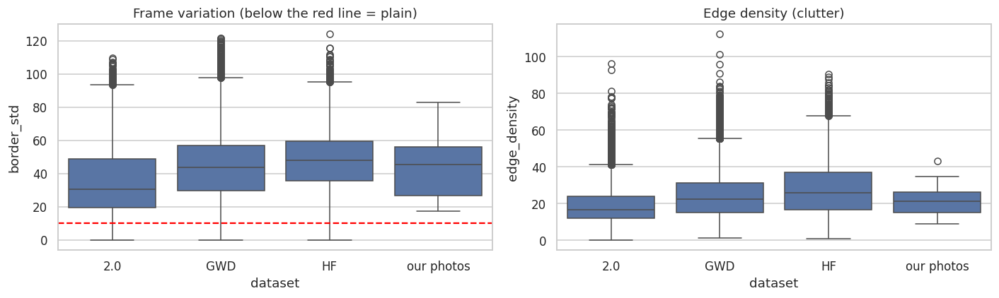

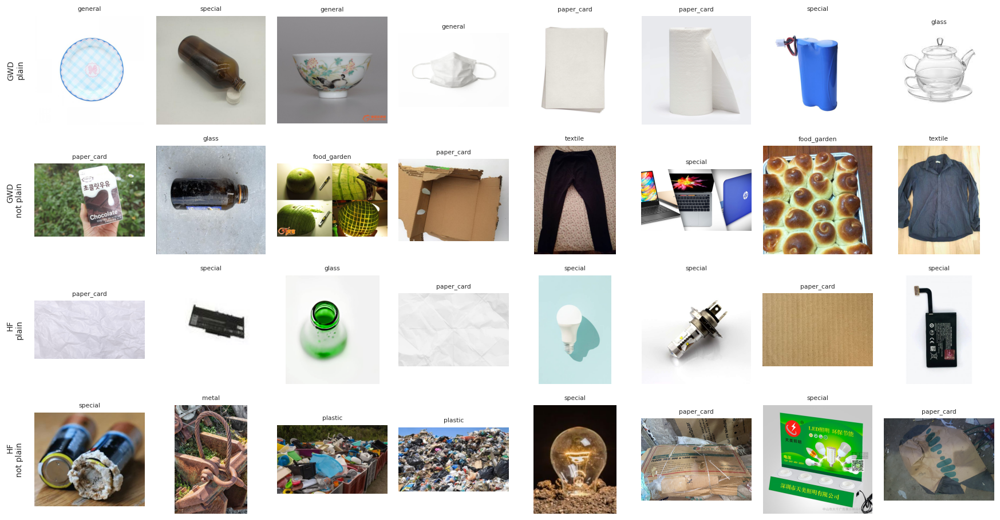

In [13]:
# ============================================================
# CELL 13 - STUDIO-STYLE (PLAIN BACKGROUND) OR REAL-WORLD SCENE?
# ============================================================
# WHAT: Measure how many images have a plain frame (white, dark or other), per dataset and per
#       class, next to 2.0 and our own photos. Show examples of each kind.
# WHY:  2.0 Section 7 found 44-48% of GD and competition `general` images on white. Catalogue shots
#       on white teach "white means general". Our own photos, and RealWaste's concrete floor, are real
#       scenes. If the new sources are mostly studio shots, they add volume but not the missing
#       real-world variety.
# HOW:  An image is "plain" when the outer 8-pixel ring of its 64x64 version is almost one
#       colour (grey-value standard deviation below PLAIN_STD). Plain AND bright (> 215) = white;
#       plain AND dark (< 60) = dark, the 2.0 thresholds. This is a rough proxy, so the
#       viewer shows plain and non-plain examples: judge the threshold by eye.
# ------------------------------------------------------------------------------------

PLAIN_STD = 10

new_props = allimg[allimg["origin"] == "new"].merge(pool4[["path"]], on="path")
view = pd.concat([allimg[allimg["origin"] == "v2"], new_props], ignore_index=True)
ph = photo_props.assign(dataset="our photos", final_class=[label_of(p) for p in photo_paths], path=[str(p) for p in photo_paths])
view = pd.concat([view, ph], ignore_index=True)
view["plain"] = view["border_std"] < PLAIN_STD
view["white"] = view["plain"] & (view["border_mean"] > 215)
view["dark"] = view["plain"] & (view["border_mean"] < 60)

DS_ORDER = ["2.0", "GWD", "HF", "our photos"]
share = view.groupby("dataset")[["plain", "white", "dark"]].mean().loc[DS_ORDER] * 100
share["images"] = view.groupby("dataset").size().loc[DS_ORDER]
print("Share of images (%) with a plain / white / dark frame:")
display(share.round(1))
print("Plain-frame share (%) per class and dataset:")
display((pd.crosstab(view["final_class"], view["dataset"], values=view["plain"], aggfunc="mean")[DS_ORDER] * 100).round(0))
print("Median clutter (edge density) and border variation per dataset:")
display(view.groupby("dataset")[["edge_density", "border_std", "brightness"]].median().loc[DS_ORDER].round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=view, x="dataset", y="border_std", order=DS_ORDER, ax=axes[0]); axes[0].axhline(PLAIN_STD, color="red", ls="--")
axes[0].set_title("Frame variation (below the red line = plain)")
sns.boxplot(data=view, x="dataset", y="edge_density", order=DS_ORDER, ax=axes[1]); axes[1].set_title("Edge density (clutter)")
plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
rows = [(ds, kind) for ds in ["GWD", "HF"] for kind in ["plain", "not plain"]]
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.1 * len(rows)))
for r, (ds, kind) in enumerate(rows):
    sub = view[(view["dataset"] == ds) & (view["plain"] == (kind == "plain"))]
    pick = sub.iloc[rng.choice(len(sub), size=min(8, len(sub)), replace=False)] if len(sub) else sub
    for c in range(8):
        axes[r, c].axis("off")
        if c < len(pick):
            with Image.open(pick.iloc[c]["path"]) as im:
                axes[r, c].imshow(im.convert("RGB"))
            axes[r, c].set_title(pick.iloc[c]["final_class"], fontsize=7)
    axes[r, 0].text(-0.1, 0.5, f"{ds}\n{kind}", transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.show()

Share of images (%) flagged as black-padded, and share with an almost fully black frame (black background):


,blackpad,black_bg
dataset,,
2.0,1.8,3.1
GWD,7.3,1.1
HF,10.4,1.2
our photos,4.2,0.0


Black-padded share (%) per class and dataset:


dataset,2.0,GWD,HF,our photos
final_class,,,,
food_garden,4.2,12.2,5.6,50.0
general,1.0,6.8,NaN,0.0
glass,1.4,17.0,6.8,0.0
metal,1.8,10.7,16.9,0.0
paper_card,1.7,4.2,5.7,0.0
plastic,1.5,4.7,5.2,0.0
special,1.8,7.6,12.3,0.0
textile,1.0,1.3,4.7,0.0


Subclasses with the most black-padded images:


share  flagged  images
dataset category              sub                                          
GWD     glass                 glass_materials        0.354      452    1276
        organic_biodegradable organic_wastes         0.219      276    1258
HF      battery_waste                                0.213      314    1477
GWD     metal                 metallic_materials     0.174      222    1276
HF      metal_waste                                  0.169      393    2325
GWD     electronic            laptops                0.169       67     397
                              electronic_components  0.168      181    1077
        medical_hazardous     masks                  0.166       66     397
        electronic            electronic_chips       0.143       64     448
HF      e_waste                                      0.134      251    1875
GWD     electronic            smartphones            0.115       25     218
        metal                 beverage_cans          0.103      145    1409

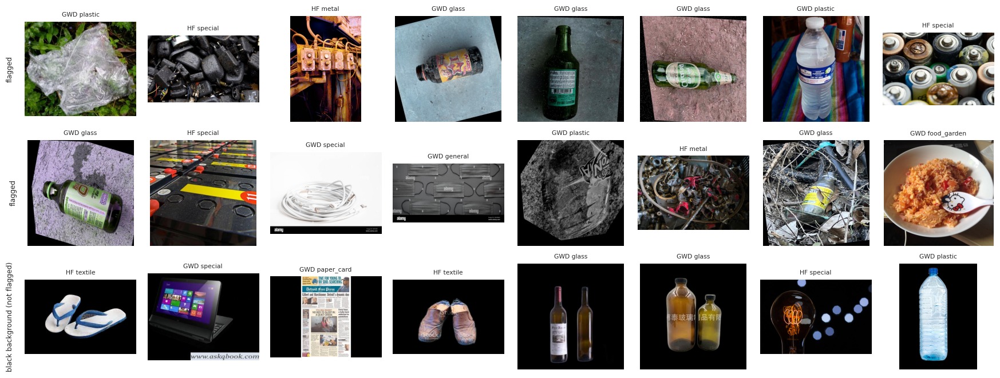

In [14]:
# ============================================================
# CELL 13b - BLACK PADDING: ROTATED AND LETTERBOXED IMAGES
# ============================================================
# WHAT: Flag images that have black corners or black bars (the padding left by rotating or letterboxing a
#       photo), count them per dataset, class and subclass, and show examples.
# WHY:  The audits in Cells 17 and 18b showed many GWD ground photos (plastic_materials, glass_materials,
#       organic_wastes, electronic_components) and HF battery images with black corners or greyscale
#       rotation. These are augmented copies made outside this notebook. Two problems: black corners
#       are a shortcut (our Pi photos never have them), and a rotated copy of a photo is not caught by the
#       hash check in Section 3, so the original and its rotated copy can land on both sides of the split.
# HOW:  On the same 64x64 centre square used for the other measures, count pixels whose brightest channel is
#       at most 12. An image is flagged when 5-60% of the outer ring is pure black and less than 25% of the
#       centre is (a fully black background is not padding, and shows as a high ring share without the flag).
#       Cell 19 drops flagged images when DROP_BLACKPAD is True.
# ------------------------------------------------------------------------------------

BLACK_RING_MIN, BLACK_RING_MAX, BLACK_CORE_MAX = 0.05, 0.60, 0.25
view["blackpad"] = (view["black_ring"].between(BLACK_RING_MIN, BLACK_RING_MAX) & (view["black_core"] < BLACK_CORE_MAX))
view["black_bg"] = (view["black_ring"] > BLACK_RING_MAX)
bp = view.set_index("path")["blackpad"]
pool4["blackpad"] = pool4["path"].map(bp).fillna(False).astype(bool)

print("Share of images (%) flagged as black-padded, and share with an almost fully black frame (black background):")
display((view.groupby("dataset")[["blackpad", "black_bg"]].mean().loc[DS_ORDER] * 100).round(1))
print("Black-padded share (%) per class and dataset:")
display((pd.crosstab(view["final_class"], view["dataset"], values=view["blackpad"], aggfunc="mean")[DS_ORDER] * 100).round(1))
sub_view = view[view["origin"] == "new"].merge(pool4[["path", "sub"]], on="path", how="left")
by_sub = (sub_view.groupby(["dataset", "category", "sub"])["blackpad"].agg(["mean", "sum", "size"])
          .rename(columns={"mean": "share", "sum": "flagged", "size": "images"}))
print("Subclasses with the most black-padded images:")
display(by_sub[by_sub["images"] >= 100].sort_values("share", ascending=False).head(12).round(3))

rng = np.random.default_rng(SEED)
rows = [("flagged", view[view["blackpad"] & (view["origin"] == "new")]), ("flagged", view[view["blackpad"] & (view["origin"] == "new")]),
        ("black background (not flagged)", view[view["black_bg"] & (view["origin"] == "new")])]
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.1 * len(rows)))
for r, (kind, sub) in enumerate(rows):
    pick_ = sub.iloc[rng.choice(len(sub), size=min(8, len(sub)), replace=False)] if len(sub) else sub
    for c in range(8):
        axes[r, c].axis("off")
        if c < len(pick_):
            with Image.open(pick_.iloc[c]["path"]) as im:
                axes[r, c].imshow(im.convert("RGB"))
            axes[r, c].set_title(f"{pick_.iloc[c]['dataset']} {pick_.iloc[c]['final_class']}", fontsize=7)
    axes[r, 0].text(-0.1, 0.5, kind, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

**Finding:** The rule flags 1.8% of 2.0 images, 7.3% of GWD, 10.4% of HF and 1 of our 24 photos (4.2%). Black backgrounds (a fully black frame) are 1.1% of GWD, 1.2% of HF and 3.1% of 2.0, and the rule leaves them alone, as the third row of the viewer shows. By class, `glass` (GWD 17%), `metal` (HF 17%, GWD 11%) and `food_garden` (GWD 12%) are hit hardest; by subclass `glass_materials` 35%, `organic_wastes` 22%, HF battery 21%, `metallic_materials` 17%, HF metal 17%, laptops 17% and electronic components 17%. The viewer shows that the rule is only about half right: about half of the 16 flagged examples have real padding (rotated glass bottles with black corners, black bars with a stock-photo strip), and the rest are naturally dark photos (black chargers, battery arrays, dark scrap), which is also why one of our own photos is flagged. Cell 19 dropped 4,156 images (8.1% of the new data): `glass` 14.3%, `metal` 13.0%, `food_garden` 10.9%, `special` 9.6%, `paper_card` 4.5%, `plastic` 4.8%, `general` 6.8%, `textile` 1.4%. No class lost a large share, but about half of what was dropped is probably usable, and the dark real-world scenes lost are the kind we want. If that matters, raise BLACK_RING_MIN in Cell 13b (for example to 0.10) or set DROP_BLACKPAD to False and re-run from Cell 13b.

In [15]:
# ============================================================
# CELL 14 - CAN A TRIVIAL CLASSIFIER NAME THE DATASET? (SOURCE-SHORTCUT TEST)
# ============================================================
# WHAT: Predict the dataset (2.0, GWD or HF) from five cheap content numbers, and compare
#       with chance.
# WHY:  If colour and clutter alone reveal the dataset, a network can learn the dataset style
#       instead of the waste, and the "improvement" from 3.0 could be a style match with the
#       test set. 2.0 Section 7 gave 58% against 25% chance for the same kind of test.
# HOW:  600 random images per dataset (balanced, so chance = 33%), random forest, 5-fold
#       cross-validation. Format features (size, file type) are left out because 2.0 stored
#       none and Section 8 removes them. A high score is a warning, not proof, since the
#       class mix also differs by dataset.
# ------------------------------------------------------------------------------------

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

content_cols = ["mean_r", "mean_g", "mean_b", "brightness", "edge_density"]
bal_sample = (view[view["dataset"].isin(["2.0", "GWD", "HF"])].sample(frac=1, random_state=SEED)
              .groupby("dataset").head(600))
for name, cols in [("content (colour, clutter)", content_cols), ("content + frame", content_cols + ["border_std", "border_mean"])]:
    acc = cross_val_score(RandomForestClassifier(200, random_state=SEED, n_jobs=-1), bal_sample[cols], bal_sample["dataset"], cv=5).mean()
    print(f"{name:28s} dataset predicted with {acc:.1%} accuracy (chance {1 / bal_sample['dataset'].nunique():.0%})")

content (colour, clutter)    dataset predicted with 46.6% accuracy (chance 33%)
content + frame              dataset predicted with 52.1% accuracy (chance 33%)


**Finding:** Raw sizes: GWD median 533×533 px (0.25 MP, 39 KB), HF median 612×408 (0.25 MP, 50 KB; aspect 1.33 against 1.00); 12.6% of GWD and 12.4% of HF have a short side under 224 px and are upscaled; a few reach 12,000 px, so the centre-crop discards a lot of the frame there. Formats are 97% (GWD) and 94% (HF) JPEG, the rest PNG. Plain frames: 5.2% of 2.0, 3.4% of GWD, 1.6% of HF, 0% of our photos, so the new sources are less studio-like than 2.0 by this proxy; the most studio-like classes are 2.0 `general` (15%) and `special` (12%), and HF `textile` (8%). Clutter and brightness put GWD closer to our photos (edge density 22.4, brightness 145.2) than 2.0 (16.7, 156.0) or HF (25.7, 125.9); our photos are 21.2 and 140.0. The proxy misses shop product shots with a soft gradient or watermarks, which the `special` audit found in GWD batteries and medicines, so treat the 3% as a lower bound. The shortcut test names the dataset with 46.6% accuracy from colour and clutter alone and 52.1% with the frame (chance 33%): a weak but real style signal, so a better score on the new test split proves little, and the comparison must rest on the frozen 2.0 test set and the real photos.

<a id="section-7"></a>
## Section 7: Visual Inspection per Class and Source

**Goal:** Look at real images. Numbers cannot show what a class contains. Check (a) each class across 2.0, GWD and Hugging Face, (b) what feeds each class, (c) the `special` class in detail, because the Hugging Face E-waste and battery classes may contain tools and toys, (d) that the excluded categories really are what we think.

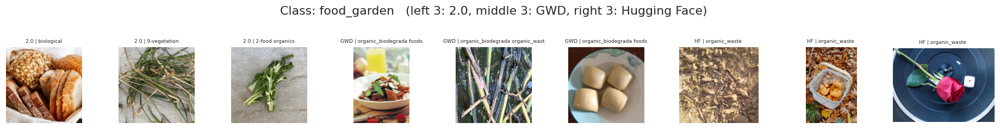

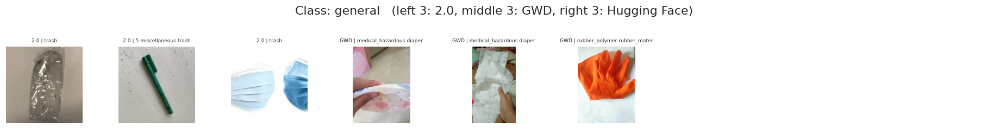

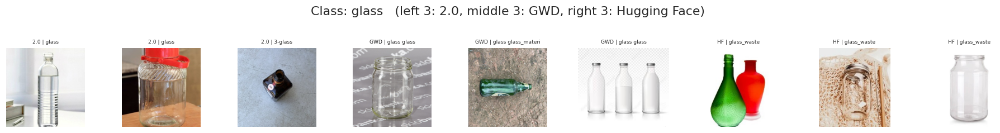

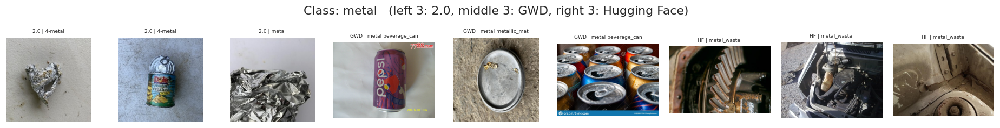

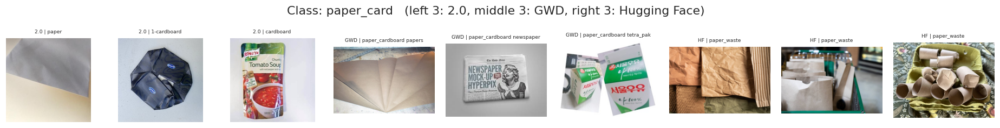

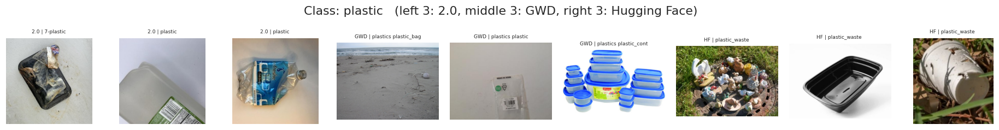

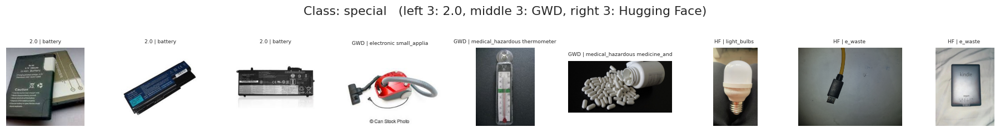

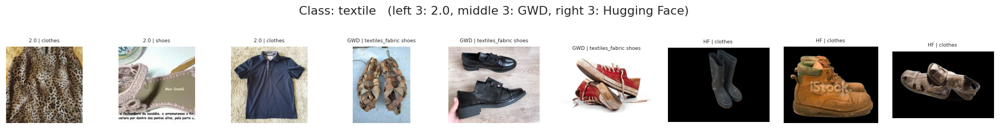

In [16]:
# ============================================================
# CELL 15 - ONE GRID PER CLASS: 2.0, GWD AND HUGGING FACE SIDE BY SIDE
# ============================================================
# WHAT: For each of the 8 classes show 3 random images from 2.0, from GWD and from Hugging Face.
# WHY:  The same class name can mean different things in different sources ("plastic" may be
#       bottles in one and bags in another, "general" may be cups or cables). Differences in
#       lighting, background and camera show up only by eye.
# HOW:  A seeded random generator picks from the kept new images (pool4) and from the 2.0
#       table. The title of a new image is its source category (and GWD subclass).
# ------------------------------------------------------------------------------------

def show_images(items, ncols, title=None, size=1.9):
    """items: list of (path, caption) -> one grid; empty cells stay blank."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.25)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (p, cap) in zip(axes.ravel(), items):
        with Image.open(p) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        ax.set_title(cap, fontsize=6)
    if title:
        fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
def pick(df, n):
    return df.iloc[rng.choice(len(df), size=min(n, len(df)), replace=False)] if len(df) else df

for cls in CLASSES:
    items = []
    for _, r in pick(v2[v2["final_class"] == cls], 3).iterrows():
        items.append((r["abs_path"], f"2.0 | {r['label']}"))
    for ds in ["GWD", "HF"]:
        for _, r in pick(pool4[(pool4["final_class"] == cls) & (pool4["dataset"] == ds)], 3).iterrows():
            items.append((r["path"], f"{ds} | {r['category'][:18]} {r['sub'][:12]}"))
    show_images(items, 9, title=f"Class: {cls}   (left 3: 2.0, middle 3: GWD, right 3: Hugging Face)")

In [17]:
# ============================================================
# CELL 16 - WHICH SOURCE CATEGORIES FEED EACH CLASS
# ============================================================
# WHAT: List, per class, the source categories that feed it and how many kept images each gives.
# WHY:  A class built from one oddly named category (for example `general` from "Misc_Trash"
#       alone) is only as good as that category. The table shows where to look in the grids.
# HOW:  crosstab of class x (dataset, category) on the kept new images.
# ------------------------------------------------------------------------------------

feed = pool4.groupby(["final_class", "dataset", "category"]).size().rename("images").reset_index()
pd.set_option("display.max_rows", 100)
display(feed)

,final_class,dataset,category,images
0,food_garden,GWD,organic_biodegradable,4402
1,food_garden,HF,organic_waste,1077
2,general,GWD,construction_ceramic_cement,771
3,general,GWD,medical_hazardous,1889
4,general,GWD,misc_trash,128
5,general,GWD,rubber_polymer,646
6,glass,GWD,glass,2817
7,glass,HF,glass_waste,1037
8,metal,GWD,metal,3820
9,metal,HF,metal_waste,2325


Categories feeding `special`:


images
dataset category                    
GWD     battery_energy_waste     969
        electronic              3344
        medical_hazardous       3175
HF      battery_waste           1477
        e_waste                 1875
        light_bulbs             2122

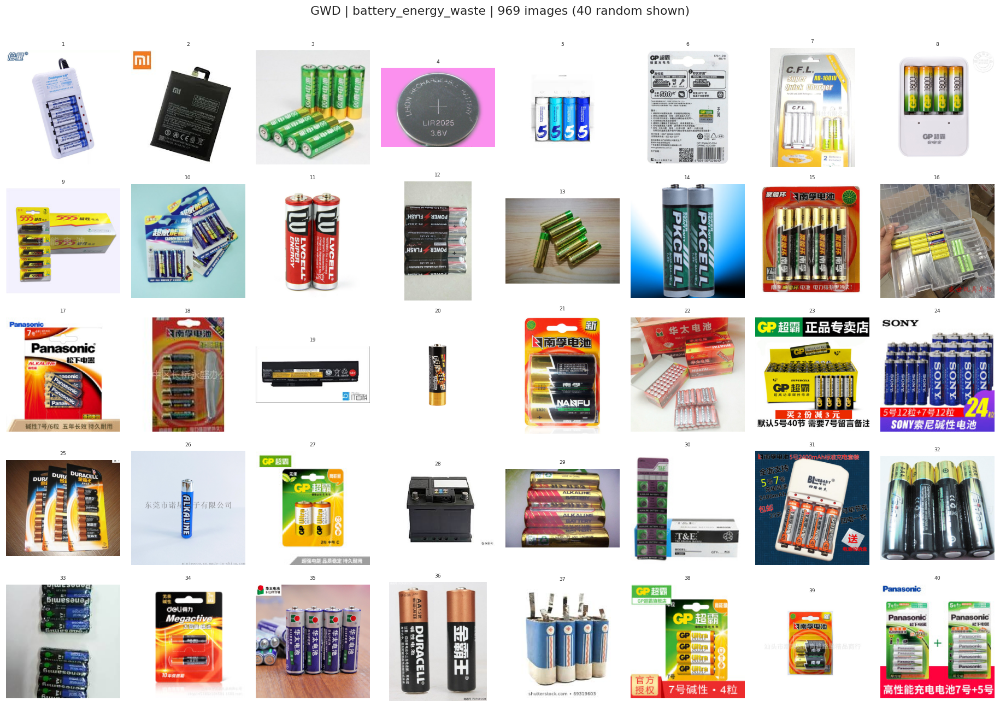

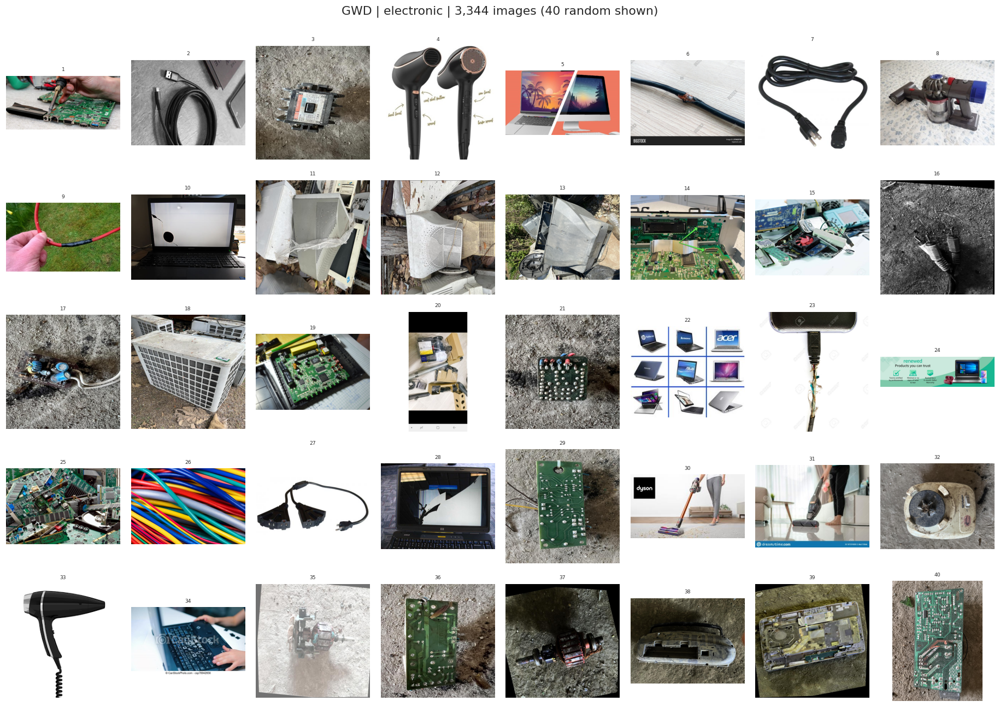

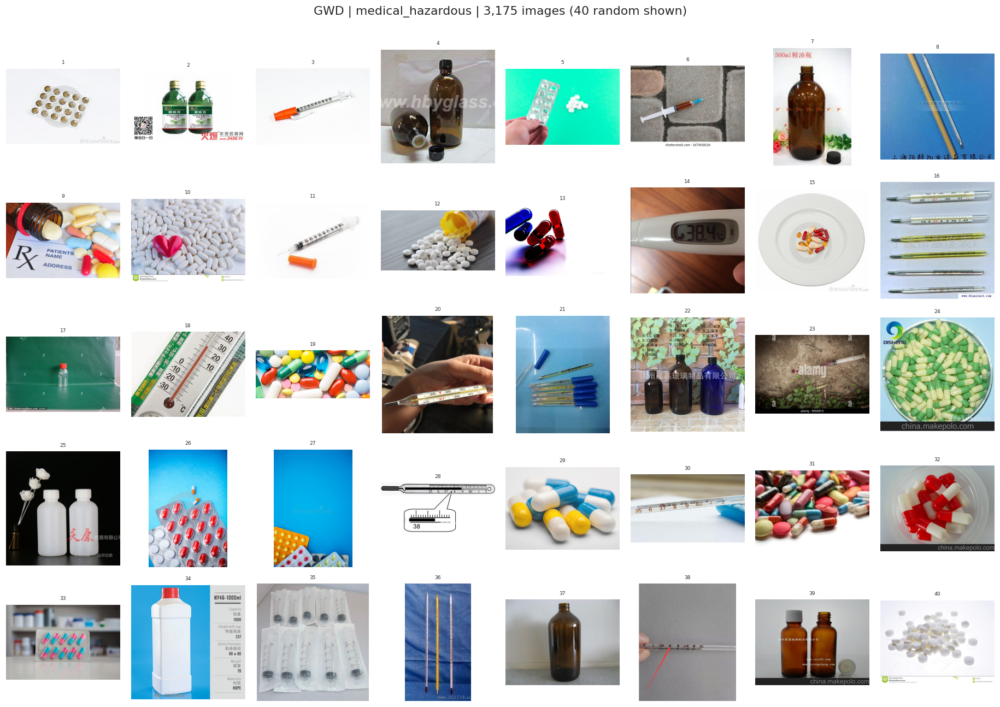

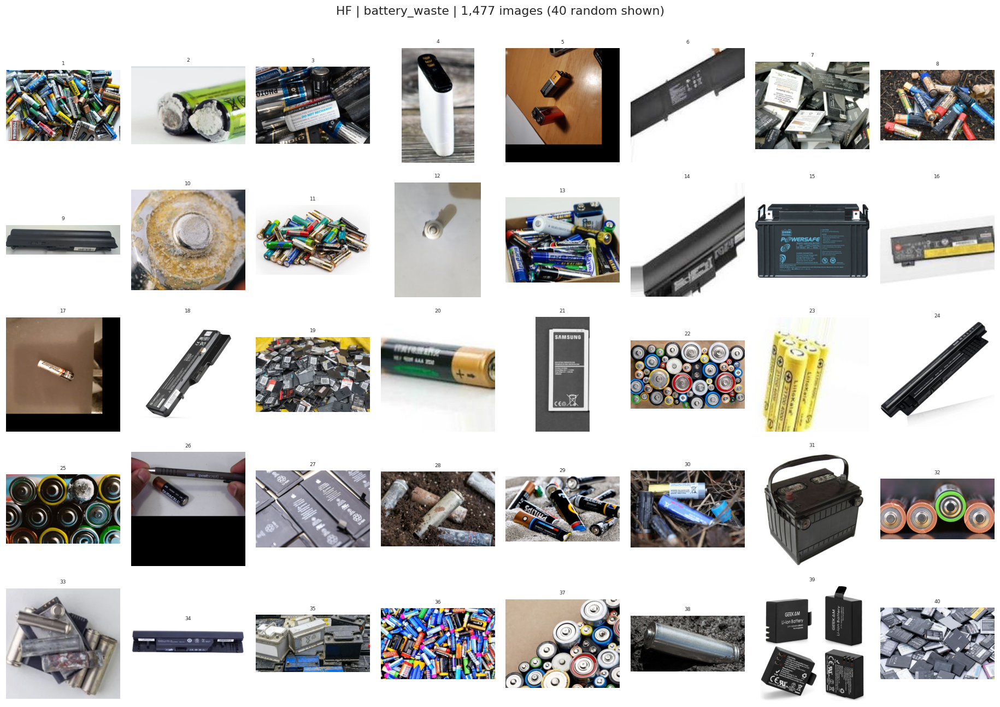

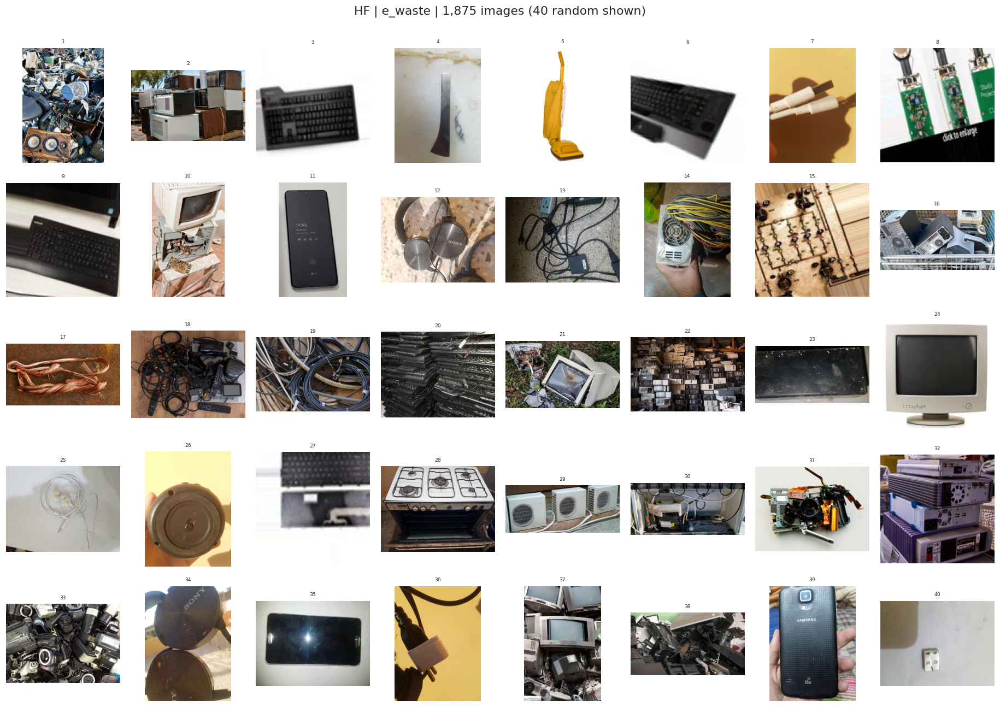

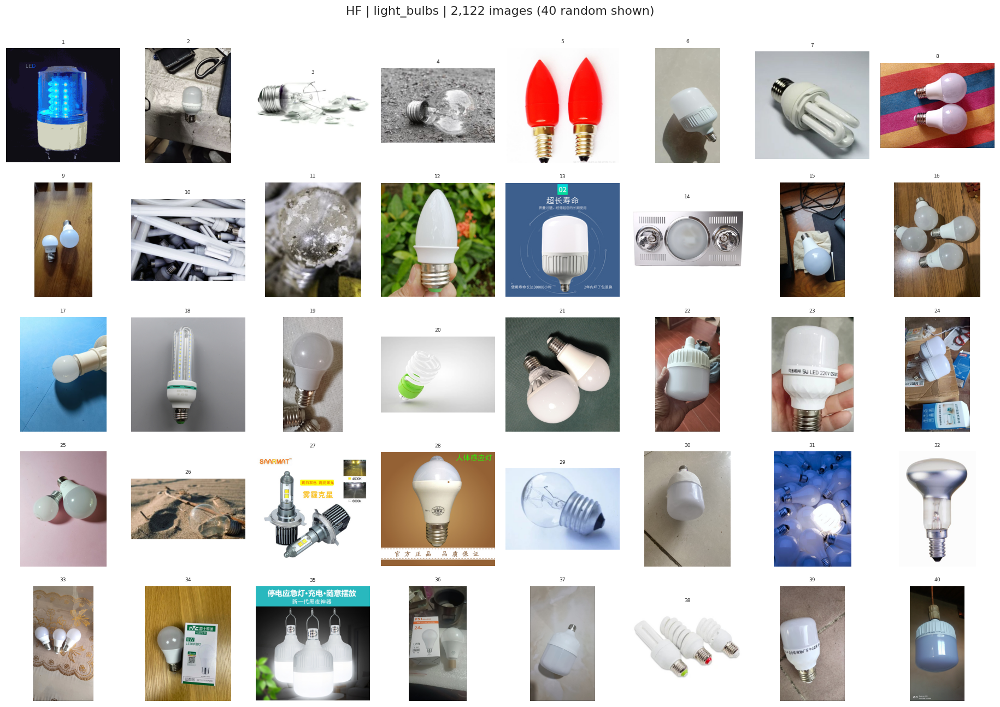

In [18]:
# ============================================================
# CELL 17 - AUDIT OF THE `special` CLASS (E-WASTE AND BATTERIES): TOOLS AND TOYS?
# ============================================================
# WHAT: For every source category mapped to `special` (including GWD medical items and HF light bulbs), show 40 random images, numbered, large
#       enough to read. Count by eye how many are NOT e-waste or batteries.
# WHY:  `special` is the thinnest class and the one with the least real-world data, so it gains most
#       from the new sources, and is also the easiest to spoil. Hugging Face "E-waste" and
#       battery classes may hold power tools, toys, whole appliances or household items. Every
#       such image teaches the model that a toy or a drill is a battery or an electrical item.
# HOW:  A random 40 per category (seeded). Write the count of wrong images per category in the
#       Finding. As a working rule: more than 10% (4 of 40) wrong means exclude that category in
#       Cell 22 (DROP_CATEGORIES); fewer means keep it and note the share as label noise. 40
#       images give a rough share only (one image = 2.5 points).
# ------------------------------------------------------------------------------------

special_feeds = pool4[pool4["final_class"] == "special"].groupby(["dataset", "category"]).size()
print("Categories feeding `special`:")
display(special_feeds.rename("images").to_frame())
for (ds, cat), n in special_feeds.items():
    sub = pool4[(pool4["final_class"] == "special") & (pool4["dataset"] == ds) & (pool4["category"] == cat)]
    sel = pick(sub, 40)
    show_images([(r["path"], f"{k + 1}") for k, (_, r) in enumerate(sel.iterrows())], 8,
                title=f"{ds} | {cat} | {n:,} images (40 random shown)", size=2.1)

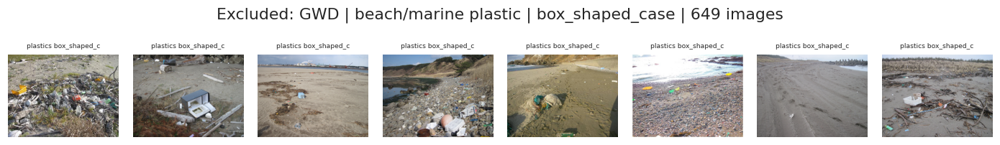

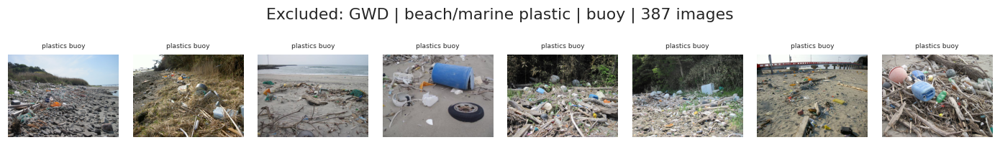

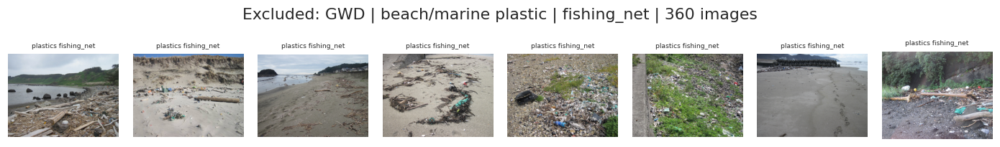

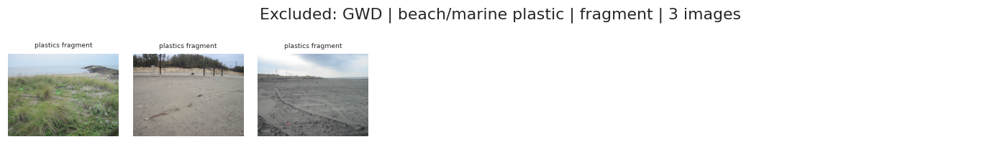

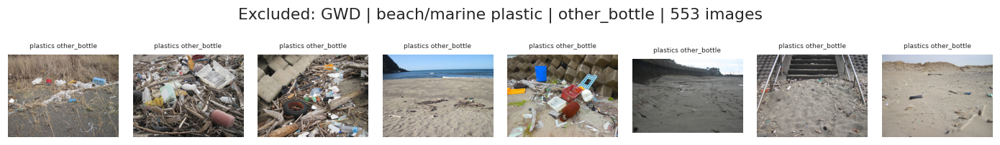

...

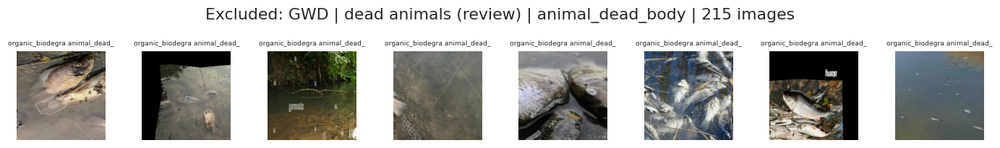

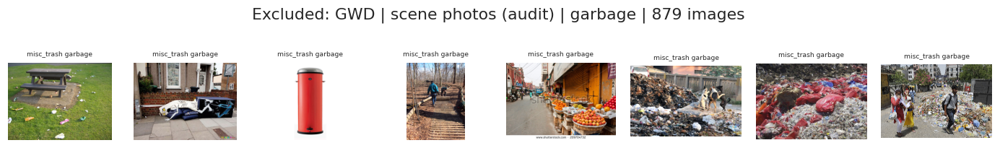

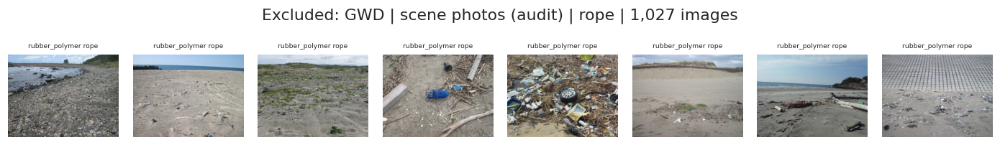

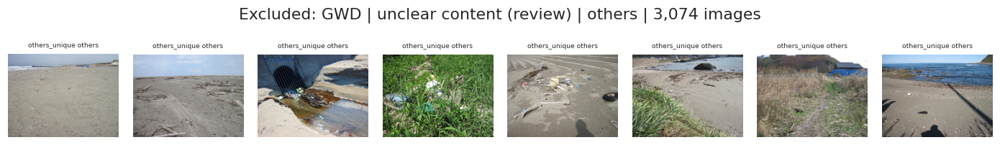

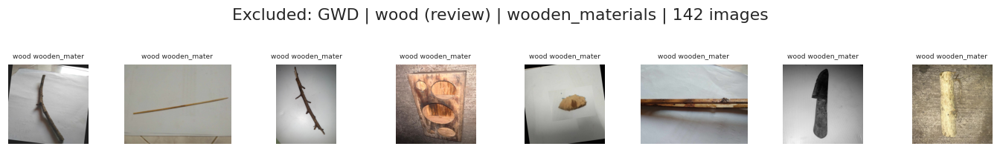

In [19]:
# ============================================================
# CELL 18 - DO THE EXCLUDED CATEGORIES LOOK LIKE WHAT WE THINK?
# ============================================================
# WHAT: For each exclusion reason, dataset and subclass, show 8 random excluded images, including the
#       "review" categories (Others_Unique, Wood, animal_dead_body).
# WHY:  An exclusion rule that is wrong throws away good data (for example "river" matching a
#       bottle photographed on a table), and the review categories were excluded only
#       because their content is unknown. If Others_Unique or Wood look like household waste,
#       they can be mapped in Cell 4.
# HOW:  Take excluded images from the full inventory (new_inv), group by dataset, reason and subclass (one row
#       of images per subclass, so a wrong BEACH_SUBS entry is easy to spot).
# ------------------------------------------------------------------------------------

excl = new_inv[(new_inv["decision"] == "excluded") & new_inv["readable"]]
for (ds, reason, sub), g in excl.groupby(["dataset", "target", "sub"]):
    sel = pick(g, 8)
    show_images([(r["path"], f"{r['category'][:16]} {r['sub'][:12]}") for _, r in sel.iterrows()], 8,
                title=f"Excluded: {ds} | {reason} | {sub or '-'} | {len(g):,} images", size=1.6)

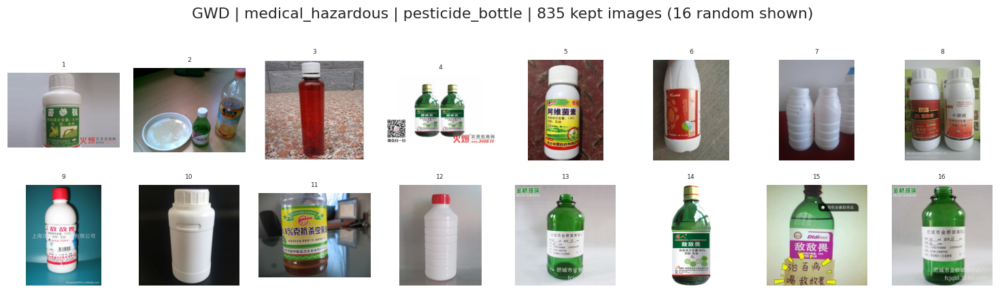

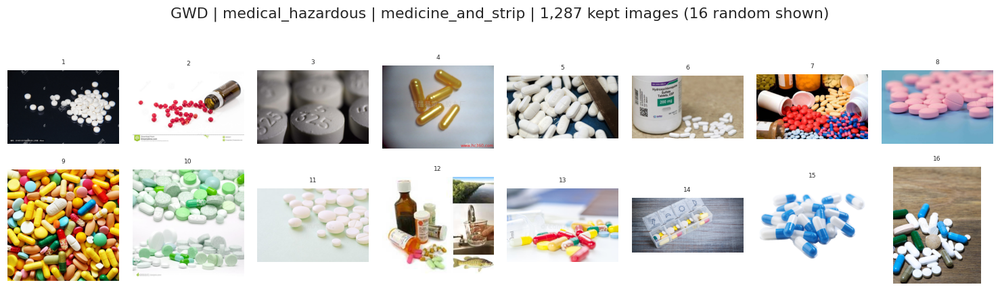

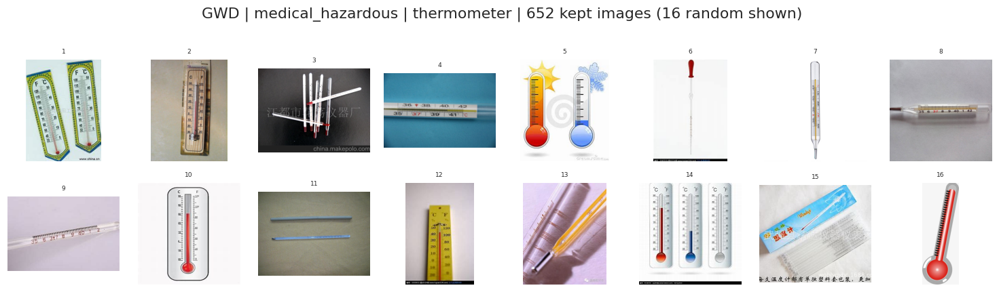

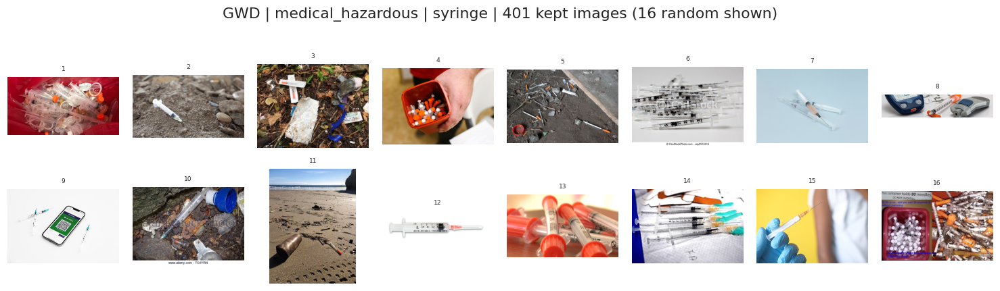

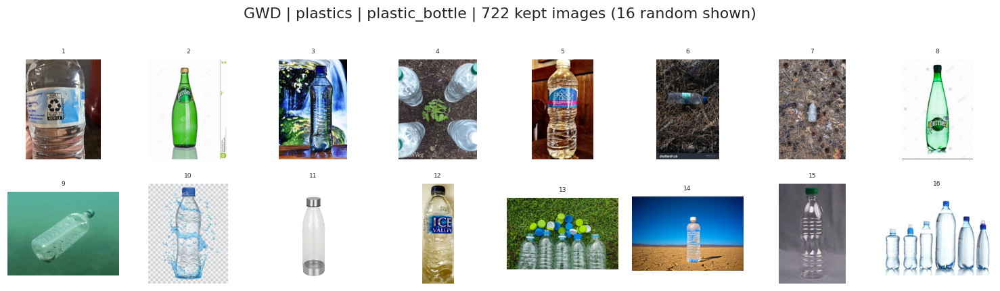

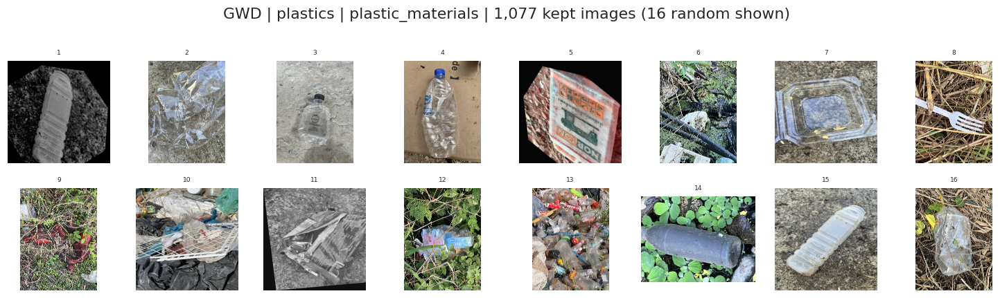

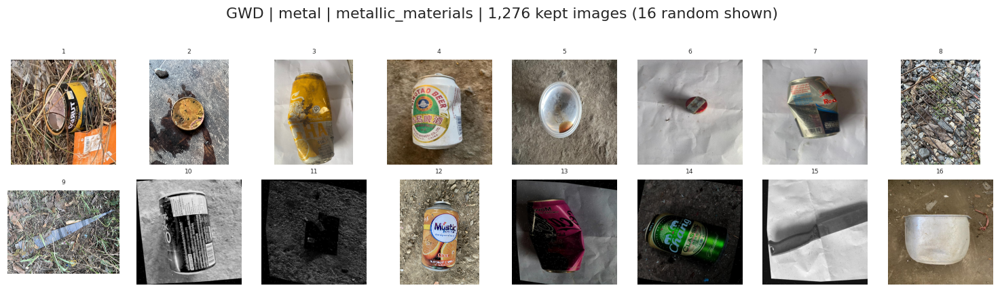

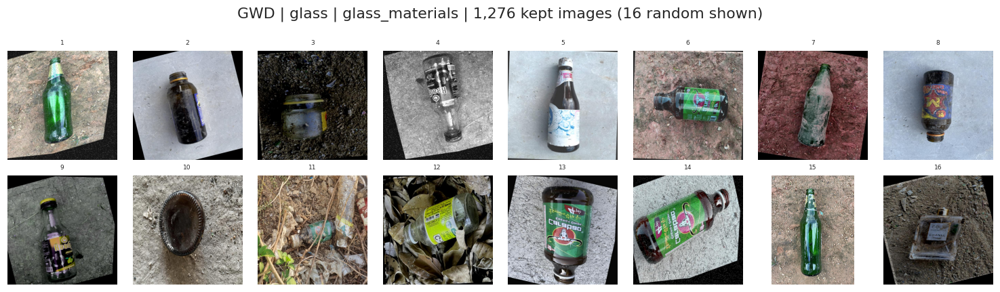

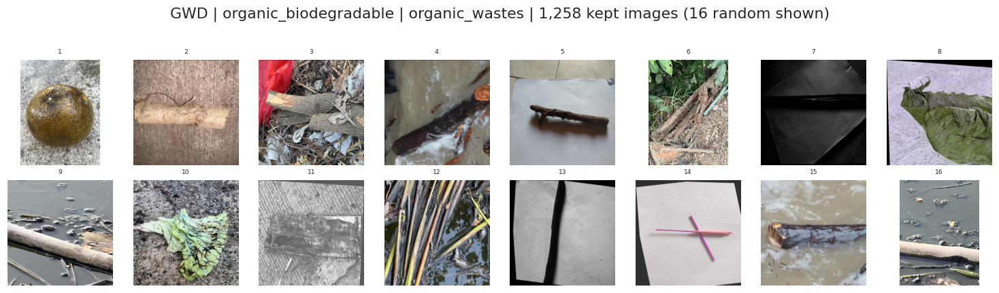

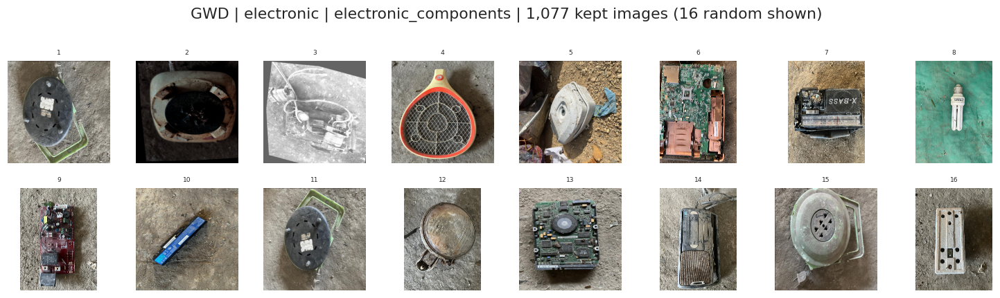

In [20]:
# ============================================================
# CELL 18b - SCENES OR SINGLE ITEMS? CHECK THE KEPT GWD SUBCLASSES THAT MAY HOLD WHOLE SCENES
# ============================================================
# WHAT: Show 16 random images from each kept GWD subclass that might contain scenes instead of one household item,
#       and from the four medical subclasses in `special` (the audit found blank bottles that look like `glass` or `plastic`).
# WHY:  Our users photograph one item. The first full run showed that misc_trash/garbage (landfills, street heaps)
#       and rubber_polymer/rope (beach debris) were all scenes; they are now excluded in Cell 4 (SCENE_SUBS) and
#       appear in the Cell 18 grids. This cell re-checks the other subclasses that could hold scenes, because a
#       class made partly of scenes teaches the model to recognise a scene, not the item, and `general` is already
#       the weakest class on real photos.
# HOW:  A seeded random 16 per subclass. Decide in the Finding: if more than a quarter are scenes, add the
#       subclass to DROP_SUBS in Cell 19 and re-run from there (DROP_CATEGORIES works at category level only).
# ------------------------------------------------------------------------------------

CHECK_SUBS = ["pesticide_bottle", "medicine_and_strip", "thermometer", "syringe", "plastic_bottle", "plastic_materials", "metallic_materials", "glass_materials", "organic_wastes", "electronic_components"]
for sub in CHECK_SUBS:
    g = pool4[(pool4["dataset"] == "GWD") & (pool4["sub"] == sub)]
    if not len(g):
        print(f"GWD | {sub}: no kept images (excluded, capped out or absent)"); continue
    sel = pick(g, 16)
    show_images([(r["path"], f"{k + 1}") for k, (_, r) in enumerate(sel.iterrows())], 8,
                title=f"GWD | {g['category'].iloc[0]} | {sub} | {len(g):,} kept images (16 random shown)", size=1.7)

**Finding:** The class grids (3 images per source) show: 2.0 and GWD are mostly single items on a plain or ground background; HF is more mixed and includes label noise (a stack of wrecked cars in `metal_waste`, crumpled foil in `paper_waste`, a full beer glass in `glass_waste`), and in the three HF `clothes` images shown the items are shoes on black. The `special` audit (40 random images each, judged by eye, one image = 2.5 points; no tools or toys in any grid): GWD electronic about 5 scenes or graphics rather than items (laptop collages, a woman vacuuming), the rest circuit boards, cables, hair dryers, CRT monitors and small appliances, which are valid e-waste; HF e-waste about 8 scrap-yard heaps rather than single items, plus a gas oven and air-conditioner units; HF light bulbs about 5 incandescent or halogen bulbs (these belong in `general`) and about 5 adverts or non-bulbs (a poster, a bathroom heater, car headlights), so about 25% questionable; GWD medical about 16 loose pills or capsules, 10 thermometers, 6 syringes and 8 blank bottles (plastic or brown glass, factory catalogue photos), so about 20% of the medical images look like ordinary bottles and could pull `glass` and `plastic` into `special`. The two battery grids were checked on run 1 (0 of 40 wrong in both; the sources are unchanged). Decision: keep all categories (nothing was added to DROP_CATEGORIES), but check the four GWD medical subclasses in Cell 18b (added after this run) and cut `pesticide_bottle` or `medicine_and_strip` with DROP_SUBS if the bottles come from there. The exclusions look right (Others_Unique is beach scenes; Wood could be `general` but has no train images). Cell 18b: `plastic_bottle` is clean apart from 2 of 16 heaps of bottles; `plastic_materials`, `metallic_materials`, `glass_materials`, `organic_wastes` and `electronic_components` are single items on the ground, but about a third to a half have black rotation corners or greyscale, which Cell 13b measures; `organic_wastes` is mostly twigs, leaves and sticks, a weak but plausible garden-waste class.

<a id="section-8"></a>
## Section 8: Stratified Split of the New Images

**Goal:** Split the new images only into train, validation and test (70/15/15, stratified), write them as standardised 224×224 JPEGs, and join them to the 2.0 table **without touching the 2.0 split**.

In [21]:
# ============================================================
# CELL 19 - SPLIT THE NEW IMAGES (2.0 SPLIT STAYS FROZEN)
# ============================================================
# WHAT: Drop any category rejected in the Section 7 audit and the black-padded images flagged in Cell 13b, then make a stratified 70/15/15
#       split of the new images and save it.
# WHY:  The 2.0 test set is the fixed yardstick for comparing a 2.0-trained and a 3.0-trained model, so
#       2.0 images keep the split they have. New images get their own split with the same
#       proportions; a new-image test set also lets us measure how a 2.0-only model copes with
#       the new sources (the domain gap in numbers). Copies were removed in Section 3, so
#       the same photo cannot sit on both sides of the split.
# HOW:  DROP_CATEGORIES holds "DATASET/category" entries (for example {"HF/e_waste"}) and DROP_SUBS holds
#       "DATASET/subclass" entries (for example {"GWD/organic_wastes"}); set them
#       after reading the Section 7 Finding and re-run from here. Stratifying on class AND dataset
#       keeps both sources in every split; strata under 20 images fall back to the class alone.
# ------------------------------------------------------------------------------------

from sklearn.model_selection import train_test_split

DROP_CATEGORIES = set()        # e.g. {"HF/e_waste"} if the audit found too many tools or toys
DROP_SUBS = set()              # e.g. {"GWD/organic_wastes"} if Cell 18b shows mostly scenes
DROP_BLACKPAD = True           # drop the images flagged in Cell 13b (black corners or bars); False keeps them

drop_mask = ((pool4["dataset"] + "/" + pool4["category"]).isin(DROP_CATEGORIES)
             | (pool4["dataset"] + "/" + pool4["sub"]).isin(DROP_SUBS)
             | (pool4["blackpad"] if DROP_BLACKPAD else False))
lost = (pd.DataFrame({"before": pool4["final_class"].value_counts(), "dropped": pool4.loc[drop_mask, "final_class"].value_counts()})
        .reindex(CLASSES).fillna(0).astype(int))
lost["% dropped"] = (lost["dropped"] / lost["before"] * 100).round(1)
display(lost)
final_new = pool4[~drop_mask].reset_index(drop=True)
print(f"Dropped after the audit: {int(drop_mask.sum()):,}  |  new images in the split: {len(final_new):,}")

key = final_new["final_class"] + "|" + final_new["dataset"]
key = key.where(key.map(key.value_counts()) >= 20, final_new["final_class"])
train, rest = train_test_split(final_new, test_size=0.30, stratify=key, random_state=SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=key.loc[rest.index], random_state=SEED)
final_new = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
final_new = final_new[["path", "final_class", "category", "sub", "dataset", "source", "split"]].reset_index(drop=True)
final_new.to_csv(WORK / "new_images_split.csv", index=False)

display(pd.crosstab(final_new["final_class"], final_new["split"], margins=True, margins_name="total"))
display(pd.crosstab(final_new["dataset"], final_new["split"], margins=True, margins_name="total"))

,before,dropped,% dropped
final_class,,,
food_garden,5479,595,10.9
general,3434,233,6.8
glass,3854,550,14.3
metal,6145,801,13.0
paper_card,7354,333,4.5
plastic,6859,329,4.8
special,12962,1239,9.6
textile,5469,76,1.4


Dropped after the audit: 4,156  |  new images in the split: 47,400


split,test,train,val,total
final_class,,,,
food_garden,733,3419,732,4884
general,480,2241,480,3201
glass,495,2313,496,3304
metal,802,3740,802,5344
paper_card,1053,4915,1053,7021
plastic,980,4571,979,6530
special,1758,8206,1759,11723
textile,809,3775,809,5393
total,7110,33180,7110,47400


split,test,train,val,total
dataset,,,,
GWD,5317,24815,5317,35449
HF,1793,8365,1793,11951
total,7110,33180,7110,47400


In [22]:
# ============================================================
# CELL 20 - STANDARDISE THE NEW IMAGES AND JOIN THEM TO 2.0
# ============================================================
# WHAT: Write every new image as a square centre-crop, 224x224, RGB, JPEG quality 95 in
#       split/class/ folders, then build final_dataset_v3_std.csv with the 2.0 rows (unchanged
#       split) and the new rows.
# WHY:  This is exactly the 2.0 recipe (2.0 Cell 10), so the old and new images have the same
#       form and the same pixels the Pi will feed the model. It also removes the format and
#       size shortcut. The origin column lets the training notebook train on 2.0 only, or on
#       2.0 + new, and test on the frozen 2.0 test set or the new test set.
# HOW:  Open, convert to RGB, crop the middle square, resize with LANCZOS, save. A thread pool
#       runs 4 images at a time. The 2.0 rows keep their rel_path (relative to the 2.0
#       verde_std folder); new rows have a rel_path relative to verde_std_new.
# ------------------------------------------------------------------------------------

OUT = WORK / "verde_std_new"
shutil.rmtree(OUT, ignore_errors=True)
SIZE, QUALITY = 224, 95

def standardise(args):
    idx, row = args
    dst = OUT / row.split / row.final_class / f"{row.dataset}_{idx:06d}.jpg"
    try:
        with Image.open(row.path) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = min(w, h)
            left, top = (w - s) // 2, (h - s) // 2
            im = im.crop((left, top, left + s, top + s)).resize((SIZE, SIZE), Image.LANCZOS)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=QUALITY)
        return str(dst.relative_to(OUT))
    except Exception:
        return None

with ThreadPoolExecutor(max_workers=4) as ex:
    final_new["rel_path"] = list(tqdm(ex.map(standardise, final_new.iterrows()), total=len(final_new), desc="Standardising"))
failed = int(final_new["rel_path"].isna().sum())
final_new = final_new.dropna(subset=["rel_path"]).reset_index(drop=True)
print(f"Written: {len(final_new):,} images  |  failed: {failed}")
print("Distinct sizes in a 300-image sample:", {Image.open(OUT / p).size for p in final_new.sample(300, random_state=SEED)["rel_path"]})

new_part = pd.DataFrame({"path": final_new["path"], "final_class": final_new["final_class"], "concept": final_new["category"],
                         "label": final_new["category"] + "/" + final_new["sub"], "src": final_new["dataset"],
                         "split": final_new["split"], "rel_path": final_new["rel_path"], "origin": "new"})
v2_part = v2[["path", "final_class", "concept", "label", "src", "split", "rel_path"]].assign(origin="v2")
v3 = pd.concat([v2_part, new_part], ignore_index=True)

same = v3[v3["origin"] == "v2"].set_index("rel_path")["split"].equals(v2.set_index("rel_path")["split"])
assert same and len(v3[v3["origin"] == "v2"]) == 14424, "the 2.0 split changed"
v3.to_csv(WORK / "final_dataset_v3_std.csv", index=False)
print("2.0 rows and their split are unchanged.")
display(pd.crosstab([v3["origin"], v3["split"]], v3["final_class"], margins=True, margins_name="total"))

Standardising: 100%|██████████| 47400/47400 [07:39<00:00, 103.18it/s]


Written: 47,400 images  |  failed: 0
Distinct sizes in a 300-image sample: {(224, 224)}
2.0 rows and their split are unchanged.


final_class   food_garden  general  glass  metal  paper_card  plastic  \
origin split                                                            
new    test           733      480    495    802        1053      980   
       train         3419     2241   2313   3740        4915     4571   
       val            732      480    496    802        1053      979   
v2     test           283      216    267    282         324      309   
       train         1318     1008   1248   1313        1513     1441   
       val            282      216    268    281         324      309   
total                6767     4641   5087   7220        9182     8589   

final_class   special  textile  total  
origin split                           
new    test      1758      809   7110  
       train     8206     3775  33180  
       val       1759      809   7110  
v2     test       149      334   2164  
       train      696     1559  10096  
       val        150      334   2164  
total           12718     7620  61824

In [23]:
# ============================================================
# CELL 21 - SAVE THE 3.0 DATASET CARD
# ============================================================
# WHAT: Write dataset_card_v3.json (class order, class weights for the 3.0 training set, image
#       size, normalisation, image folders, settings used) and zip the new image folder.
# WHY:  The training notebook must use the same class order as 2.0 (otherwise predictions map to
#       the wrong names) and weights that match the data it trains on. Recording the settings
#       (cap, dropped categories, thresholds) makes the dataset reproducible and citable in the
#       report. The zip is a fallback if the folder is awkward to attach.
# HOW:  Weights = n_total / (n_classes x n_class) on the training rows of 2.0 + new. The 2.0
#       images stay in the 2.0 notebook output; the new ones are in verde_std_new.
# ------------------------------------------------------------------------------------

train_v3 = v3[v3["split"] == "train"]["final_class"].value_counts().reindex(CLASSES)
train_v2 = v3[(v3["split"] == "train") & (v3["origin"] == "v2")]["final_class"].value_counts().reindex(CLASSES)
w3 = [round(float(train_v3.sum() / (len(CLASSES) * train_v3[c])), 4) for c in CLASSES]

card_v3 = {"classes": CLASSES, "class_weights_v3_train": w3,
           "class_weights_v2_train": card_v2["class_weights"], "image_size": 224,
           "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225],
           "csv": "final_dataset_v3_std.csv", "origin_column": "v2 = 2.0 image, new = GWD or Hugging Face image",
           "v2_image_dir": "verde-data-analysis-2-0/verde_std", "new_image_dir": "verde_std_new",
           "path_column": "rel_path (join with the image folder of its origin)",
           "counts": {o: {s: int(((v3["origin"] == o) & (v3["split"] == s)).sum()) for s in ["train", "val", "test"]} for o in ["v2", "new"]},
           "settings": {"ratio_max": RATIO_MAX, "drop_categories": sorted(DROP_CATEGORIES), "drop_subs": sorted(DROP_SUBS), "drop_blackpad": DROP_BLACKPAD, "cand_bits": CAND_BITS,
                        "corr_min": CORR_MIN, "loose_bits": LOOSE_BITS, "loose_corr": LOOSE_CORR, "plain_std": PLAIN_STD,
                        "seed": SEED, "real_photos": len(photo_paths)}}
json.dump(card_v3, open(WORK / "dataset_card_v3.json", "w"), indent=2)
shutil.make_archive(str(WORK / "verde_std_new"), "zip", str(OUT))

print("Training images per class: 2.0 only vs 2.0 + new")
display(pd.DataFrame({"2.0 train": train_v2, "3.0 train": train_v3, "weight 3.0": w3}, index=CLASSES))
print(f"Imbalance ratio of the 3.0 training set: {train_v3.max() / train_v3.min():.2f}x")
print("Saved: final_dataset_v3_std.csv, dataset_card_v3.json, verde_std_new/, verde_std_new.zip")

Training images per class: 2.0 only vs 2.0 + new


,2.0 train,3.0 train,weight 3.0
food_garden,1318,4737,1.1420
general,1008,3249,1.6650
glass,1248,3561,1.5191
metal,1313,5053,1.0706
paper_card,1513,6428,0.8416
plastic,1441,6012,0.8998
special,696,8902,0.6077
textile,1559,5334,1.0142


Imbalance ratio of the 3.0 training set: 2.74x
Saved: final_dataset_v3_std.csv, dataset_card_v3.json, verde_std_new/, verde_std_new.zip


**Finding:** New images split 33,180 train / 7,110 val / 7,110 test (47,400; GWD 24,815 / 5,317 / 5,317, HF 8,365 / 1,793 / 1,793), so both sources are in every split. Final 3.0 sizes per class: food_garden 6,767, general 4,641, glass 5,087, metal 7,220, paper_card 9,182, plastic 8,589, special 12,718, textile 7,620; 61,824 in total (new share 76.7%). The 2.0 rows and their split are unchanged (the assertion passed). No category or subclass was dropped after the audit; the 4,156 images removed in this cell are the black-padded ones (Section 6, Cell 13b). The 3.0 training set (43,276 images) has a 2.74x imbalance, with class weights from 0.61 (`special`) to 1.67 (`general`).

<a id="section-9"></a>
## Section 9: Findings, Limitations & the 2.0 vs 3.0 Training Plan

**Goal:** Put the whole funnel in one table, state what the dataset can and cannot support, and fix in advance how EfficientNet-B0 T3 will be trained on 2.0 and on 3.0 and how the two will be compared. Writing the rules before seeing results is what keeps the comparison honest.

dataset,GWD,HF,total
1 found,65599,28840,94439
2 readable,65583,28840,94423
3 mapped to our 8 classes,53442,28840,82282
4 after exact duplicates,53420,14154,67574
5 after copies of 2.0 and of each other,38449,13348,51797
6 after leakage check,38224,13332,51556
7 after class cap,38224,13332,51556
8 final (after audit),35449,11951,47400


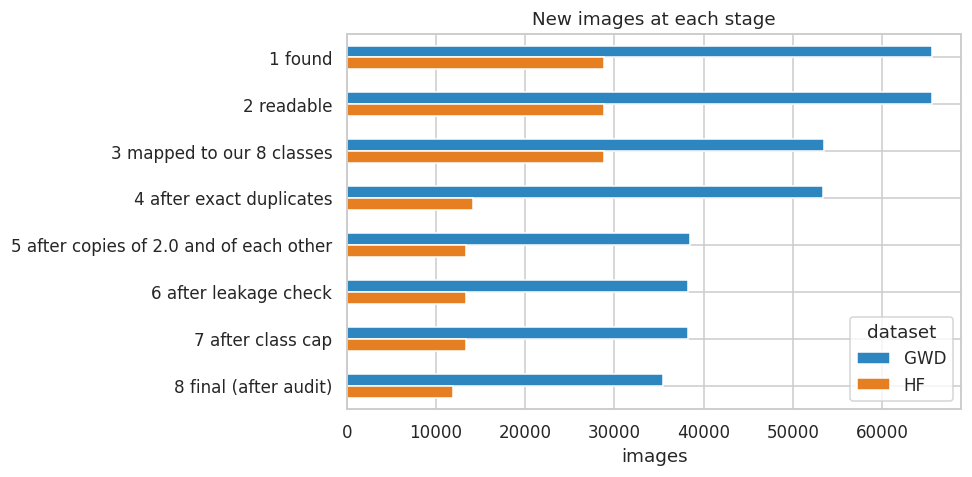

2.0 base: 14,424 images (frozen)  |  3.0 total: 61,824 images  |  new share: 76.7%


In [24]:
# ============================================================
# CELL 22 - THE FUNNEL: FROM RAW SOURCE IMAGES TO THE FINAL NEW IMAGES
# ============================================================
# WHAT: Count the new images at every stage, per dataset, and chart the funnel.
# WHY:  The report needs one table that answers "how many images did each source give, and why
#       did the rest go?". It also shows which stage removed the most (expected: deduplication
#       for GWD, because it contains RealWaste and GD).
# HOW:  Every number is the size of a table built in Sections 1 to 8, split by dataset.
# ------------------------------------------------------------------------------------

stages = [("1 found", new_inv), ("2 readable", new_inv[new_inv["readable"]]),
          ("3 mapped to our 8 classes", pool), ("4 after exact duplicates", pool1),
          ("5 after copies of 2.0 and of each other", pool2), ("6 after leakage check", pool3),
          ("7 after class cap", pool4), ("8 final (after audit)", final_new)]
funnel = pd.DataFrame({name: df.groupby("dataset").size() for name, df in stages}).fillna(0).astype(int).T
funnel["total"] = funnel.sum(axis=1)
display(funnel)
funnel.to_csv(WORK / "funnel.csv")

ax = funnel[["GWD", "HF"]].plot(kind="barh", figsize=(9, 4.5), color=["#2e86c1", "#e67e22"])
ax.invert_yaxis(); ax.set_xlabel("images"); ax.set_title("New images at each stage")
plt.tight_layout(); plt.show()
print(f"2.0 base: {len(v2):,} images (frozen)  |  3.0 total: {len(v3):,} images  |  new share: {len(final_new) / len(v3):.1%}")

**Finding:** 47,400 of 94,439 images found (50%) survived: mapping removed 12,141 (including 16 unreadable), exact duplicates 14,708 and near-copies 15,777 (14,272 of them copies of 2.0), leakage 241, the cap nothing and the black-padding rule 4,156. Final sizes per class run from 4,641 (`general`) to 12,718 (`special`), imbalance 2.74x in training. By clutter and brightness GWD is closer to our photos than 2.0 is (Section 6), HF is busier and darker, and the plain-frame proxy puts both below 2.0. The `special` audit found no tools or toys; the issues are scenes and heaps, blank bottles in the medical images, incandescent bulbs and adverts among the bulbs, black rotation padding and watermarked shop shots, partly handled by the exclusions and the Cell 13b rule.

### Limitations

- **Labels come from folder names.** Every image has one label taken from its source folder. GWD notes that multi-object scenes are not captured, and the mapping to our 8 classes is by category name (Section 2), so a wrong rule moves thousands of images at once. The visual inspection (Section 7) is the only check on the content.
- **Duplicate detection is not complete.** A 64-bit hash plus a thumbnail check finds copies of the same centre crop. Mirrored, rotated, differently cropped or heavily edited copies are not found. Datasets that were merged from the same sources (GWD contains RealWaste and GD) are the most likely place for such leftovers.
- **Leakage was checked against two reference sets only**: the 2.0 test set and the 24 real photos, at a looser setting than Section 3. It was not checked against photos we may take in future, so every new photo set needs the same check.
- **Licences are mixed or unknown.** GWD is CC BY 4.0 as an archive, with source licences that include non-commercial and share-alike terms, and its paper says modification is not permitted. The Hugging Face dataset states no licence or origin. This is acceptable for coursework, but the images should not be redistributed, and any commercial use of a model trained on them needs the source terms checked.
- **The studio-vs-real measure is a proxy.** "Plain frame" is a rule on the outer ring of the image, not a judgement of the scene. The 40-image audit of `special` gives a rough share only (one image = 2.5 points).
- **Standardisation costs information.** The centre-crop to 224×224 cuts the edges of wide images and shrinks large ones, exactly as the Pi does. Small items in a wide scene can be lost.
- **Scene photos, porcelain and black padding were handled by judgement from small grids.** `misc_trash/garbage` and `rubber_polymer/rope` were excluded after 16 random images of each were all scenes, which says nothing about the few images that are single items. `construction/porcelin` (plates, bowls) was mapped to `general` by the 2.0 ceramics rule. Images with black corners or bars (rotation or letterbox padding) are dropped by a rule on a 64×64 version (Cell 13b), so about half of the images it flagged in run 2 were natural dark photos (one of our 24 photos was flagged) and some padded ones are kept; the rotated copy of a kept photo is not caught by the hash check.
- **The GWD release has fewer images than its paper.** The downloaded archive and the Kaggle copy both hold 65,599 images against the 89,807 claimed (73%), `Wood` has no train images, and the splits are 79.5 / 10.2 / 10.3 instead of 70 / 10 / 20. We cannot tell which source datasets lost images, so GWD class mixes may differ from the paper's.
- **Medical and light-bulb images were mapped by judgement, not excluded.** GWD bandages, diapers, gloves and masks went to `general`; medicines and blister strips, syringes, thermometers and pesticide bottles went to `special`, as did Hugging Face light bulbs. In England some items differ (medicines go back to a pharmacy, sharps need a sharps bin, incandescent and halogen bulbs are general waste), so the app advice must not say "bin it" for these. Adding them also makes `special` even more dependent on the new sources.
- **GWD content is international.** Its categories and items come from many countries and do not follow England's bin rules. Class names were mapped, but whether an item belongs in a UK bin still depends on the advice step and the local council.
- **Three categories were excluded by default for review** (GWD Others_Unique, Wood and animal_dead_body), and nine GWD plastics subclasses were excluded as beach or marine plastic by name (BEACH_SUBS), which was judged from their names and the image grids, not checked image by image, and the exclusion rules were written from the category names in the GWD paper, not from the real folder tree.
- **The new test split is in-distribution.** It comes from the same sources as the new training images, so a good score on it does not show that the model works on our camera. Only the real photos do, and there are only 24 of them (one photo = 4.2 points).

### Plan: EfficientNet-B0 T3 on 2.0 vs 3.0

**Question:** Does training on 2.0 + the new images improve EfficientNet-B0 T3 on real photos, without hurting it on the frozen 2.0 test set?

| | Model A (baseline) | Model B (3.0) |
|---|---|---|
| Training images | 2.0 train (10,096) | 2.0 train + new train |
| Recipe | T3: fine-tune the whole network, resampling, AdamW (lr 3e-4, weight decay 1e-4), cosine schedule, 12 epochs, label smoothing 0.1, batch 64, RealWaste boost 2.0, ImageNet normalisation | identical |
| Seeds | 42, 7, 123 | 42, 7, 123 |
| Best epoch chosen by | macro-F1 on the **2.0 validation set** | the **same 2.0 validation set** |
| Never used for training or choosing an epoch | 2.0 test set, new test split, the 24 real photos | the same |

Choosing the epoch on the 2.0 validation set for both models means the new data cannot help B pick a better epoch for itself. The recipe and seeds are identical, so the only difference is the training data. Model A is the existing T3 result; re-run it in the same notebook as B so the two are compared under one environment (times are comparable only inside one notebook).

**Test sets and what each shows**

| Test set | Size | What it shows | Rule fixed in advance |
|---|---|---|---|
| Frozen 2.0 test | 2,164 | no regression on the old yardstick | B must stay within 1 point of A (seed-to-seed noise was 0.3 to 1 point) |
| New test split | see Cell 19 | how A copes with the new sources (domain gap in numbers) and whether B learned them | informative only; B is expected to win, A's drop is the finding |
| 24 real photos | 24 | the target domain | B must get at least 2 more photos right than A (mean of 3 seeds) **and** must not have more confident-wrong answers (≥ 60% confidence) than A |

A gap of less than 2 photos is "cannot tell". If B passes the first and third rows, 3.0 becomes the training set for the Pi and phone photo fine-tuning. If the photos show no gain, the conclusion is that more public data does not close the gap and that our own Pi and phone photos are needed (the fine-tuning plan stays as it is).

**Controls and checks**
- Report accuracy, macro-F1, "not sure" rate and confident-wrong rate for A and B on every test set, as mean ± range over the 3 seeds.
- If B wins on the photos, run two cheap extra trainings to see which source helped: 2.0 + GWD only, and 2.0 + Hugging Face only. If B loses on the photos, look at which classes (`special` first) fall and check the Section 7 audit for label noise.
- Per-class table on the photos (it rests on 1 to 7 photos per class, so it only points to where to look).
- Do not tune the cap, the dropped categories or the thresholds after seeing the photo results. If they must change, record it and re-run both models.

**Outputs of the training notebook**: a results table (A vs B × 3 test sets × 3 seeds), the per-photo predictions, and the chosen checkpoint with its `class_names` in the 2.0 order.

### Summary

The 3.0 dataset has 61,824 images: the frozen 14,424 from 2.0 plus 47,400 new ones (GWD 35,449, Hugging Face 11,951). The new data is smaller than it looks: 14,272 GWD and HF images (about a quarter of GWD) were already in 2.0, half of HF is byte-identical to GWD, and 2,131 copies of 2.0 test images were removed. The audits found real value in `special` (12,718 images against 995), `general` and `plastic`, and real problems (scenes, black padding, watermarked shop shots, blank bottles among the medical images, a few label-noise images in HF metal and paper). GWD is the more useful source for the real-photo problem: more images, closer to our photos in clutter and brightness, and the only source for `general`; HF mainly adds batteries, e-waste and light bulbs (5,474 of its 11,951). Whether any of this helps on real photos is decided by the 2.0-vs-3.0 comparison, not by these counts.

**How to use the result**
1. Commit this notebook (Save & Run All), then use `final_dataset_v3_std.csv`, `verde_std_new/` and `dataset_card_v3.json` as inputs to the training notebook.
2. Use the funnel table, the licence table and the audit counts in the logbook and in the report's data section.
3. Write the Findings only from the executed outputs, then re-run Section 8 if the `special` audit adds entries to DROP_CATEGORIES.

**Next steps:** run the 2.0-vs-3.0 training comparison; photograph new Pi and phone images (kept in two folders: fine-tuning and held-out) and fine-tune the winner on them; check the chosen model on the Pi and the phone.